# Manuscript 280-E — Early-warning prediction of requirement volatility

**Reproducible analysis notebook.** Running all cells top to bottom regenerates the simulated dataset and every table, figure and number reported in the manuscript and Supplementary Material.

> **All data are simulated.** The generator encodes assumed relationships, so the models can only show how well those relationships are recovered. They do not establish real-world determinants of requirement volatility.

| Setting | Value |
|---|---|
| Master seed | 42 (`random_state = 42` everywhere; robustness reruns use seeds 1–10) |
| Prediction cutoff | 25% of planned duration |
| Target | *RVI*<sub>post</sub> = 100 × later changes / size ≥ 2.0 |
| Run time (full settings) | about 40 min on 2 CPU cores; set `QUICK = True` for a smoke test |

Outputs are written to `outputs/` (CSV tables, 300-dpi figures, `results.json`) and shown inline.

## 0. Environment and configuration

In [1]:
# Versions used for the reported results:
# scikit-learn 1.9.1 · xgboost 3.4.1 · lightgbm 4.7.0 · shap 0.53.0 · statsmodels 0.15.0
# !pip install scikit-learn==1.9.1 xgboost==3.4.1 lightgbm==4.7.0 shap==0.53.0 statsmodels==0.15.0

In [2]:
import argparse
import json
import os
import warnings
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from scipy import stats
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor
import xgboost as xgb
import lightgbm as lgb
import shap

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans",
})

from IPython.display import display, Image, Markdown
%matplotlib inline

In [3]:
OUTDIR = "outputs"            # where tables, figures and results.json are written
SEED = 42                     # master seed
QUICK = False                 # True = 8-draw search for a fast smoke test (numbers will differ)
ROBUSTNESS_SEEDS = list(range(1, 11))

outdir, seed, quick, robustness_seeds = OUTDIR, SEED, QUICK, ROBUSTNESS_SEEDS

## 1. Generator specification

Every parameter that affects the simulated data lives in `GeneratorSpec` (Supplementary Table S1). The latent monthly change rate *r* drives both early changes (before the cutoff) and later changes (after it). That shared rate is what makes early warning possible, and it is also why the target depends on the predictors by construction.

In [4]:
@dataclass
class GeneratorSpec:
    n_projects: int = 11_000

    # --- categorical attributes (independent draws) ---------------------------
    industry_levels: tuple = ("Finance", "Manufacturing", "Retail", "Healthcare",
                              "Public sector", "Telecom")
    industry_probs: tuple = (0.22, 0.20, 0.18, 0.15, 0.13, 0.12)
    methodology_levels: tuple = ("Agile", "Hybrid", "Waterfall")
    methodology_probs: tuple = (0.45, 0.30, 0.25)
    distribution_levels: tuple = ("Co-located", "Hybrid", "Distributed")
    distribution_probs: tuple = (0.35, 0.40, 0.25)
    engagement_levels: tuple = ("Low", "Medium", "High")       # ordinal
    engagement_probs: tuple = (0.25, 0.45, 0.30)
    pm_maturity_levels: tuple = (1, 2, 3, 4, 5)                 # ordinal (CMMI-style)
    pm_maturity_probs: tuple = (0.10, 0.25, 0.30, 0.25, 0.10)

    # --- Project_Size (function points): Normal truncated by rejection ----------
    size_mu: float = 530.0
    size_sigma: float = 276.0
    size_bounds: tuple = (50, 1200)

    # --- Complexity_Score (1-100): depends on size and industry -----------------
    #   C = round(clip(cx_intercept + cx_size_slope*Size + industry_offset + N(0, cx_sd), 1, 100))
    cx_intercept: float = 30.0
    cx_size_slope: float = 0.05
    cx_sd: float = 15.0
    cx_industry_offset: dict = field(default_factory=lambda: {
        "Finance": 5.0, "Manufacturing": 0.0, "Retail": -5.0, "Healthcare": 5.0,
        "Public sector": 8.0, "Telecom": 3.0})

    # --- Team_Size: shifted Poisson whose mean depends on size, then capped -----
    #   T = min(3 + Poisson(Size / team_fp_per_member), 25)
    team_min: int = 3
    team_fp_per_member: float = 75.0
    team_max: int = 25

    # --- Estimated_Duration_Months: log-normal with size/complexity in log-mean -
    #   ln D ~ N(ln(dur_base) + dur_size_slope*Size + dur_cx_slope*C, dur_log_sd),
    #   rounded to whole months and clipped to [4, 36]
    dur_base: float = 3.0
    dur_size_slope: float = 0.0011
    dur_cx_slope: float = 0.004
    dur_log_sd: float = 0.35
    dur_bounds: tuple = (4, 36)

    # --- Estimated_Budget (USD) = Team x Duration x monthly cost per FTE --------
    #   monthly cost per FTE ~ N(9000, 1500), truncated at 5000
    fte_cost_mu: float = 9000.0
    fte_cost_sd: float = 1500.0
    fte_cost_min: float = 5000.0

    # --- Developer_Experience_Years: Gamma(shape, scale), rounded, clipped -------
    exp_shape: float = 4.0
    exp_scale: float = 1.9
    exp_bounds: tuple = (1, 20)

    # --- Requirement-change process --------------------------------------------
    # Latent monthly change rate r_i (changes per 100 FP per month):
    #   ln r_i = b0 + b_cx*(C-50) + b_eng*(Eng-1) + b_pm*(PM-3) + b_exp*(Exp-8)
    #            + method_offset + distribution_offset + industry_rate_offset
    #            + b_interact * 1[C>70 and Distributed] + u_i,
    #   u_i ~ N(0, latent_sd)   (unobserved project instability)
    # Eng is coded Low=0, Medium=1, High=2.
    b0: float = np.log(0.30)
    b_cx: float = 0.012
    b_eng: float = -0.25
    b_pm: float = -0.12
    b_exp: float = -0.03
    method_offset: dict = field(default_factory=lambda: {
        "Agile": 0.15, "Hybrid": 0.0, "Waterfall": -0.10})
    distribution_offset: dict = field(default_factory=lambda: {
        "Co-located": 0.0, "Hybrid": 0.05, "Distributed": 0.15})
    industry_rate_offset: dict = field(default_factory=lambda: {
        "Finance": 0.10, "Manufacturing": 0.0, "Retail": 0.05, "Healthcare": 0.0,
        "Public sector": 0.15, "Telecom": 0.0})
    b_interact: float = 0.20
    latent_sd: float = 0.45

    # Observation window: the first `cutoff_fraction` of the planned duration.
    cutoff_fraction: float = 0.25
    # Early changes  E_i ~ Poisson(r_i * Size/100 * t_c)
    # Later changes  L_i ~ NegBin(mean = r_i * later_drift * Size/100 * (D - t_c), dispersion k)
    later_drift: float = 0.75          # change rate after the cutoff relative to before
    nb_dispersion_k: float = 8.0       # Var = mu + mu^2/k

    # Target: RVI_post = 100 * L / Size  (later changes per 100 FP; >= 0 by construction)
    # High volatility  <=>  RVI_post >= rvi_threshold  (fixed before any model was trained)
    rvi_threshold: float = 2.0


SPEC = GeneratorSpec()

INITIATION_NUMERIC = ["Project_Size", "Team_Size", "Estimated_Duration_Months",
                      "Estimated_Budget", "Complexity_Score", "Developer_Experience_Years",
                      "PM_Maturity"]
NOMINAL = ["Industry", "Methodology", "Team_Distribution"]
ORDINAL = ["Stakeholder_Engagement"]
ENGINEERED_INITIATION = ["Complexity_Per_Developer", "Experience_Impact"]
EARLY_SIGNAL = ["Early_Requirement_Changes", "Early_Change_Density", "Early_Change_Intensity"]

FEATURES_CUTOFF = INITIATION_NUMERIC + ENGINEERED_INITIATION + EARLY_SIGNAL + ORDINAL + NOMINAL
FEATURES_INITIATION = INITIATION_NUMERIC + ENGINEERED_INITIATION + ORDINAL + NOMINAL

## 2. Data generation and engineered features

`check_feature_bounds()` asserts that every engineered feature respects the maximum its formula allows. This check would have caught the earlier `Change_Intensity` error.

In [5]:
def _truncnorm_rejection(rng, mu, sd, lo, hi, n):
    out = rng.normal(mu, sd, n)
    bad = (out < lo) | (out > hi)
    while bad.any():
        out[bad] = rng.normal(mu, sd, bad.sum())
        bad = (out < lo) | (out > hi)
    return out


def generate_dataset(seed: int, spec: GeneratorSpec = SPEC) -> pd.DataFrame:
    """Generate the synthetic project portfolio.  Returns raw variables, the
    simulated outcome (Later_Requirement_Changes, RVI_post) and the binary target."""
    rng = np.random.default_rng(seed)
    n = spec.n_projects

    industry = rng.choice(spec.industry_levels, n, p=spec.industry_probs)
    method = rng.choice(spec.methodology_levels, n, p=spec.methodology_probs)
    distrib = rng.choice(spec.distribution_levels, n, p=spec.distribution_probs)
    engagement = rng.choice(spec.engagement_levels, n, p=spec.engagement_probs)
    pm = rng.choice(spec.pm_maturity_levels, n, p=spec.pm_maturity_probs)

    size = np.round(_truncnorm_rejection(rng, spec.size_mu, spec.size_sigma,
                                         *spec.size_bounds, n)).astype(int)

    cx_off = np.array([spec.cx_industry_offset[i] for i in industry])
    complexity = np.clip(np.round(spec.cx_intercept + spec.cx_size_slope * size + cx_off
                                  + rng.normal(0, spec.cx_sd, n)), 1, 100).astype(int)

    team = np.minimum(spec.team_min + rng.poisson(size / spec.team_fp_per_member),
                      spec.team_max).astype(int)

    log_d = (np.log(spec.dur_base) + spec.dur_size_slope * size + spec.dur_cx_slope * complexity
             + rng.normal(0, spec.dur_log_sd, n))
    duration = np.clip(np.round(np.exp(log_d)), *spec.dur_bounds).astype(int)

    fte_cost = _truncnorm_rejection(rng, spec.fte_cost_mu, spec.fte_cost_sd,
                                    spec.fte_cost_min, np.inf, n)
    budget = np.round(team * duration * fte_cost, 2)

    experience = np.clip(np.round(rng.gamma(spec.exp_shape, spec.exp_scale, n)),
                         *spec.exp_bounds).astype(int)

    eng_code = np.array([spec.engagement_levels.index(e) for e in engagement])
    u = rng.normal(0, spec.latent_sd, n)
    log_r = (spec.b0 + spec.b_cx * (complexity - 50) + spec.b_eng * (eng_code - 1)
             + spec.b_pm * (pm - 3) + spec.b_exp * (experience - 8)
             + np.array([spec.method_offset[m] for m in method])
             + np.array([spec.distribution_offset[d] for d in distrib])
             + np.array([spec.industry_rate_offset[i] for i in industry])
             + spec.b_interact * ((complexity > 70) & (distrib == "Distributed"))
             + u)
    rate = np.exp(log_r)                                 # changes / 100 FP / month

    t_c = spec.cutoff_fraction * duration                # months observed before prediction
    early = rng.poisson(rate * size / 100 * t_c)
    mu_later = rate * spec.later_drift * size / 100 * (duration - t_c)
    k = spec.nb_dispersion_k
    later = rng.negative_binomial(k, k / (k + mu_later))  # NegBin(mean mu, dispersion k)
    rvi_post = 100 * later / size

    df = pd.DataFrame({
        "Project_ID": np.arange(1, n + 1),
        "Industry": industry, "Methodology": method, "Team_Distribution": distrib,
        "Stakeholder_Engagement": engagement, "PM_Maturity": pm,
        "Project_Size": size, "Complexity_Score": complexity, "Team_Size": team,
        "Estimated_Duration_Months": duration, "Estimated_Budget": budget,
        "Developer_Experience_Years": experience,
        "Cutoff_Months": t_c,
        "Early_Requirement_Changes": early,
        # ---- outcome-side variables (never used as predictors) ----
        "Latent_Change_Rate": rate,
        "Later_Requirement_Changes": later,
        "RVI_post": rvi_post,
    })
    df["High_Volatility"] = (df["RVI_post"] >= spec.rvi_threshold).astype(int)
    return add_engineered_features(df)


def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    """Engineered features.  Formulas are exactly those printed in the manuscript."""
    df = df.copy()
    df["Complexity_Per_Developer"] = df["Complexity_Score"] / df["Team_Size"]
    df["Experience_Impact"] = df["Developer_Experience_Years"] * df["Complexity_Score"] / 100
    df["Early_Change_Density"] = 100 * df["Early_Requirement_Changes"] / df["Project_Size"]
    df["Early_Change_Intensity"] = df["Early_Requirement_Changes"] / df["Cutoff_Months"]
    check_feature_bounds(df)
    return df


def check_feature_bounds(df: pd.DataFrame) -> None:
    """Fail loudly if any engineered feature exceeds the maximum its inputs allow.
    (This is the check that would have caught the Change_Intensity error.)"""
    tol = 1e-9
    mx = df.max(numeric_only=True)
    mn = df.min(numeric_only=True)
    assert df["Complexity_Per_Developer"].max() <= mx["Complexity_Score"] / mn["Team_Size"] + tol
    assert df["Experience_Impact"].max() <= (mx["Developer_Experience_Years"]
                                             * mx["Complexity_Score"] / 100 + tol)
    assert df["Early_Change_Density"].max() <= 100 * mx["Early_Requirement_Changes"] / mn["Project_Size"] + tol
    assert df["Early_Change_Intensity"].max() <= mx["Early_Requirement_Changes"] / mn["Cutoff_Months"] + tol
    # row-level identity checks
    np.testing.assert_allclose(df["Early_Change_Intensity"] * df["Cutoff_Months"],
                               df["Early_Requirement_Changes"])
    np.testing.assert_allclose(df["Complexity_Per_Developer"] * df["Team_Size"], df["Complexity_Score"])
    assert (df["RVI_post"] >= 0).all()

## 3. Leakage-safe pre-processing, model zoo and evaluation helpers

All encoders and scalers sit inside the scikit-learn pipeline, so they are refitted within every cross-validation fold. `metrics_from_cm()` derives every metric from the confusion matrix and asserts agreement with scikit-learn.

In [6]:
def make_preprocessor(features: list[str], scale: bool) -> ColumnTransformer:
    num = [f for f in features if f not in NOMINAL + ORDINAL]
    nom = [f for f in features if f in NOMINAL]
    ordc = [f for f in features if f in ORDINAL]
    num_tf = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num_tf, num),
        ("ord", OrdinalEncoder(categories=[list(SPEC.engagement_levels)]), ordc),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nom),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


def model_zoo(seed: int):
    """Estimator, whether it needs scaling, and its randomized-search space.
    The same search budget, folds and scoring are used for every model."""
    from scipy.stats import loguniform, randint, uniform
    return {
        "Logistic Regression": (
            LogisticRegression(max_iter=5000, solver="lbfgs", random_state=seed), True,
            {"clf__C": loguniform(1e-3, 1e2)}),
        "Decision Tree": (
            DecisionTreeClassifier(random_state=seed), False,
            {"clf__max_depth": randint(2, 16), "clf__min_samples_leaf": randint(5, 200),
             "clf__criterion": ["gini", "entropy"]}),
        "Random Forest": (
            RandomForestClassifier(random_state=seed, n_jobs=2), False,
            {"clf__n_estimators": randint(200, 601), "clf__max_depth": [None, 6, 10, 14, 20],
             "clf__min_samples_leaf": randint(1, 50), "clf__max_features": ["sqrt", 0.3, 0.5, 0.8]}),
        "LightGBM": (
            lgb.LGBMClassifier(random_state=seed, n_jobs=2, verbose=-1), False,
            {"clf__n_estimators": randint(100, 801), "clf__learning_rate": loguniform(0.01, 0.2),
             "clf__num_leaves": randint(8, 128), "clf__min_child_samples": randint(5, 100),
             "clf__subsample": uniform(0.6, 0.4), "clf__subsample_freq": [1],
             "clf__colsample_bytree": uniform(0.6, 0.4), "clf__reg_lambda": loguniform(1e-3, 10)}),
        "XGBoost": (
            xgb.XGBClassifier(random_state=seed, n_jobs=2, eval_metric="logloss",
                              tree_method="hist", scale_pos_weight=1.0), False,
            {"clf__n_estimators": randint(100, 801), "clf__learning_rate": loguniform(0.01, 0.2),
             "clf__max_depth": randint(2, 9), "clf__min_child_weight": loguniform(0.5, 20),
             "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.6, 0.4),
             "clf__reg_alpha": loguniform(1e-3, 5), "clf__reg_lambda": loguniform(0.1, 10)}),
    }


def metrics_from_cm(y_true, y_prob, thr):
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    # cross-check against sklearn so the table can never disagree with the matrix
    assert np.isclose(acc, accuracy_score(y_true, y_pred))
    assert np.isclose(prec, precision_score(y_true, y_pred, zero_division=0))
    assert np.isclose(rec, recall_score(y_true, y_pred, zero_division=0))
    assert np.isclose(f1, f1_score(y_true, y_pred, zero_division=0))
    return {"threshold": thr, "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
            "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
            "Specificity": tn / (tn + fp),
            "ROC_AUC": roc_auc_score(y_true, y_prob), "Brier": brier_score_loss(y_true, y_prob),
            "LogLoss": log_loss(y_true, y_prob)}


def expected_calibration_error(y, p, n_bins=10):
    bins = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece


def paired_bootstrap_auc(y, p_full, p_reduced, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if y[i].min() == y[i].max():
            continue
        diffs.append(roc_auc_score(y[i], p_full[i]) - roc_auc_score(y[i], p_reduced[i]))
    diffs = np.array(diffs)
    return float(np.mean(diffs)), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))


def risk_band(p):
    return pd.cut(p, [-np.inf, 0.30, 0.60, 0.85, np.inf], right=False,
                  labels=["Low", "Moderate", "High", "Critical"])

## 4. Figure helpers (diagrams and risk-band plot)

In [7]:
def _box(ax, x, y, w, h, text, fc="#ffffff", ec="#333333", fs=10.5, weight="normal", ls="-"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.01,rounding_size=0.015",
                                fc=fc, ec=ec, lw=1.2, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, weight=weight,
            wrap=True)


def _arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", lw=1.3, color="#333333"))


def fig_conceptual(path):
    fig, ax = plt.subplots(figsize=(11, 7.4))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    # timeline
    ax.plot([0.05, 0.95], [0.90, 0.90], color="#333333", lw=1.5)
    for x, lab in [(0.05, "Initiation\n(t = 0)"), (0.30, "Prediction cutoff\n(t_c = 0.25 x planned duration)"),
                   (0.95, "Planned completion\n(t = D)")]:
        ax.plot([x, x], [0.885, 0.915], color="#333333", lw=1.5)
        ax.text(x, 0.93, lab, ha="center", va="bottom", fontsize=10)
    ax.text(0.175, 0.875, "observation window", ha="center", va="top", fontsize=9.5, style="italic")
    ax.text(0.625, 0.875, "prediction horizon (outcome period)", ha="center", va="top",
            fontsize=9.5, style="italic")
    # inputs (left column, stacked)
    _box(ax, 0.02, 0.53, 0.40, 0.29,
         "Initiation-time attributes\nProject size, team size, estimated duration,\n"
         "estimated budget, complexity score, developer\nexperience, PM maturity, stakeholder engagement,\n"
         "methodology, industry, team distribution\n+ complexity per developer, experience impact",
         fc="#eef3fb", fs=9.8)
    _box(ax, 0.02, 0.31, 0.40, 0.17,
         "Early-phase change signals (observed before t_c)\nEarly requirement changes\n"
         "Early change density, early change intensity", fc="#fdf2e6", fs=9.8)
    # outcome
    _box(ax, 0.66, 0.44, 0.32, 0.22,
         "Later-phase requirement volatility\n(t_c to D)\nRVI_post >= 2 changes per 100 FP\n"
         "-> High volatility (1/0)", fc="#eaf6ee", fs=10)
    _arrow(ax, 0.42, 0.675, 0.66, 0.60)
    _arrow(ax, 0.42, 0.395, 0.66, 0.50)
    ax.text(0.54, 0.535, "P1-P4\n(Section 3.2)", ha="center", va="center", fontsize=9.5,
            bbox=dict(fc="white", ec="none", pad=1))
    _box(ax, 0.66, 0.30, 0.32, 0.10,
         "Model output: P(high volatility),\nSHAP explanation (log-odds), risk band", fc="#ffffff", fs=9.8)
    _arrow(ax, 0.82, 0.44, 0.82, 0.40)
    _box(ax, 0.02, 0.03, 0.96, 0.21,
         "Simulated mechanism (Supplementary S1): a latent monthly change rate depends on complexity, "
         "stakeholder engagement,\nPM maturity, developer experience, methodology, team distribution, "
         "industry and an unobserved project-specific term.\nThe SAME rate drives early and later changes, "
         "so the experiment tests recovery of this assumed mechanism,\nnot real-world causation.",
         fc="#f5f5f5", fs=9.2, ls="--")
    fig.savefig(path, bbox_inches="tight"); plt.close(fig)


def fig_pipeline(path):
    fig, ax = plt.subplots(figsize=(10, 6.8))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    W, H = 0.27, 0.085
    left = [("1. Project data at cutoff\n(initiation attributes +\nearly change counts)", 0.88),
            ("2. Feature engineering\n(row-wise formulas; no\nparameters learned)", 0.74),
            ("3. Stratified 80/20 split\n(random_state = 42)", 0.60)]
    for t, y in left:
        _box(ax, 0.03, y, W, H, t, fc="#eef3fb")
    for (_, y0), (_, y1) in zip(left[:-1], left[1:]):
        _arrow(ax, 0.165, y0, 0.165, y1 + H)
    # training branch
    _box(ax, 0.38, 0.60, W + 0.05, H, "Training set (8,800)", fc="#fdf2e6", weight="bold")
    _box(ax, 0.38, 0.40, W + 0.05, 0.15,
         "4. Inside each of 5 CV folds:\nfit encoders / scaler on fold-train\n"
         "-> fit model -> score fold-validation\n(50-draw randomized search,\nscoring = log loss)",
         fc="#fdf2e6", fs=10)
    _box(ax, 0.38, 0.25, W + 0.05, 0.10,
         "5. Refit best pipeline on full\ntraining set; choose recall-oriented\nthreshold from out-of-fold predictions",
         fc="#fdf2e6", fs=10)
    _arrow(ax, 0.30, 0.630, 0.38, 0.630)
    _arrow(ax, 0.54, 0.60, 0.54, 0.55)
    _arrow(ax, 0.54, 0.40, 0.54, 0.35)
    # test branch
    _box(ax, 0.74, 0.60, 0.23, H, "Test set (2,200)\nheld out until step 6", fc="#eaf6ee", weight="bold")
    _box(ax, 0.74, 0.25, 0.23, 0.25,
         "6. Single evaluation:\nconfusion matrix,\nmetrics, ROC, calibration,\nSHAP (log-odds),\nrisk bands",
         fc="#eaf6ee", fs=10)
    ax.plot([0.30, 0.33, 0.33, 0.855], [0.665, 0.665, 0.715, 0.715], color="#333333", lw=1.3)
    _arrow(ax, 0.855, 0.715, 0.855, 0.685)
    _arrow(ax, 0.855, 0.60, 0.855, 0.50)
    _arrow(ax, 0.70, 0.30, 0.74, 0.30)
    _box(ax, 0.20, 0.04, 0.60, 0.13,
         "7. Decision support (proposed, not evaluated with users):\nprobability + explanation + "
         "illustrative risk band for project review",
         fc="#f5f5f5", fs=10.5, ls="--")
    _arrow(ax, 0.855, 0.25, 0.70, 0.17)
    fig.savefig(path, bbox_inches="tight"); plt.close(fig)


# =============================================================================
# 4. MAIN EXPERIMENT
# =============================================================================

def plot_risk_bands(p, band_tab, path):
    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    ax.hist(p, bins=40, color="#9db7e0", edgecolor="white")
    for t in (0.30, 0.60, 0.85):
        ax.axvline(t, color="#333333", ls="--", lw=1)
    ymax = ax.get_ylim()[1]
    ax.set_ylim(0, ymax * 1.45)
    for (lo, hi), lab in zip([(0, .30), (.30, .60), (.60, .85), (.85, 1)],
                             ["Low", "Moderate", "High", "Critical"]):
        r = band_tab.loc[lab]
        ax.text((lo + hi) / 2, ymax * 1.40,
                f"{lab}\nn = {int(r.n)}\n({r.percent:.1f}%)\nobserved\nhigh = {100*r.observed_high_rate:.1f}%",
                ha="center", va="top", fontsize=9.5)
    ax.set_xlabel("Predicted probability of high later-phase volatility (XGBoost, test set n = 2,200)")
    ax.set_ylabel("Number of projects")
    fig.tight_layout(); fig.savefig(path, bbox_inches="tight"); plt.close(fig)


def describe_numeric(df, cols):
    d = df[cols].describe(percentiles=[0.25, 0.5, 0.75]).T
    d = d.rename(columns={"25%": "Q1", "50%": "Median", "75%": "Q3"})
    return d[["mean", "std", "min", "Q1", "Median", "Q3", "max"]]

## 5. Output folders and results container

In [8]:
os.makedirs(outdir, exist_ok=True)
fig_dir = os.path.join(outdir, "figures"); os.makedirs(fig_dir, exist_ok=True)
tab_dir = os.path.join(outdir, "tables"); os.makedirs(tab_dir, exist_ok=True)
R = {"seed": seed, "versions": {"xgboost": xgb.__version__, "shap": shap.__version__,
                                "lightgbm": lgb.__version__,
                                "sklearn": __import__("sklearn").__version__}}
n_iter = 8 if quick else 50

## 6. Generate the dataset and descriptive tables (Tables 1–2)

In [9]:
# ---------------- data ----------------
df = generate_dataset(seed)
df.to_csv(os.path.join(outdir, "synthetic_projects_seed42.csv"), index=False)
with open(os.path.join(outdir, "generator_spec.json"), "w") as f:
    json.dump({k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(SPEC).items()},
              f, indent=2, default=float)

y_all = df["High_Volatility"].values
R["n"] = len(df)
R["prevalence"] = float(y_all.mean())
R["n_high"] = int(y_all.sum()); R["n_low"] = int((1 - y_all).sum())
R["rvi_ties_at_threshold"] = int(np.isclose(df["RVI_post"], SPEC.rvi_threshold).sum())
R["rvi_zero"] = int((df["RVI_post"] == 0).sum())
R["rvi_quantiles"] = df["RVI_post"].quantile([0.25, 0.5, 0.75]).to_dict()
R["rvi_unique_values"] = int(df["RVI_post"].nunique())

# descriptive tables
num_cols = (INITIATION_NUMERIC + ["Cutoff_Months", "Early_Requirement_Changes"]
            + ENGINEERED_INITIATION + ["Early_Change_Density", "Early_Change_Intensity"]
            + ["Later_Requirement_Changes", "RVI_post", "High_Volatility"])
desc = describe_numeric(df, num_cols)
desc.to_csv(os.path.join(tab_dir, "table1_descriptives.csv"))
cat_rows = []
for c in NOMINAL + ORDINAL + ["PM_Maturity"]:
    vc = df[c].value_counts().sort_index()
    hv = df.groupby(c)["High_Volatility"].mean()
    for lvl, cnt in vc.items():
        cat_rows.append({"Variable": c, "Level": lvl, "n": int(cnt),
                         "Percent": 100 * cnt / len(df), "High_volatility_rate": hv[lvl]})
pd.DataFrame(cat_rows).to_csv(os.path.join(tab_dir, "table2_categorical.csv"), index=False)

# theoretical vs observed for team size (comment on Poisson SD)
R["team_size_note"] = {
    "observed_mean": float(df.Team_Size.mean()), "observed_sd": float(df.Team_Size.std()),
    "conditional_poisson_sd_at_mean_size": float(np.sqrt(SPEC.size_mu / SPEC.team_fp_per_member)),
    "explanation": "Team size is 3 + Poisson(Size/75). Because the Poisson mean varies with "
                   "project size, the marginal SD exceeds a single-Poisson SD (law of total variance)."}
lam = df.Project_Size / SPEC.team_fp_per_member
R["team_size_note"]["law_of_total_variance_sd"] = float(np.sqrt(lam.mean() + lam.var()))

In [10]:
display(pd.read_csv(os.path.join(tab_dir, 'table1_descriptives.csv'), index_col=0).round(2))
display(pd.read_csv(os.path.join(tab_dir, 'table2_categorical.csv')).round(3))
print('Prevalence of high volatility:', round(R['prevalence'], 4), '| ties at threshold:', R['rvi_ties_at_threshold'])
print('Team-size SD check:', {k: (round(v, 3) if isinstance(v, float) else v) for k, v in R['team_size_note'].items() if k != 'explanation'})

,mean,std,min,Q1,Median,Q3,max
Project_Size,546.94,244.40,51.00,365.00,539.00,719.00,1198.00
Team_Size,10.29,4.24,3.00,7.00,10.00,13.00,25.00
Estimated_Duration_Months,7.87,3.86,4.00,5.00,7.00,10.00,36.00
Estimated_Budget,801887.74,678540.42,69859.70,338314.49,595907.43,1045951.24,9075467.82
Complexity_Score,59.57,19.30,1.00,46.00,60.00,73.00,100.00
Developer_Experience_Years,7.62,3.74,1.00,5.00,7.00,10.00,20.00
PM_Maturity,3.00,1.13,1.00,2.00,3.00,4.00,5.00
Cutoff_Months,1.97,0.97,1.00,1.25,1.75,2.50,9.00
Early_Requirement_Changes,6.59,9.66,0.00,1.00,3.00,8.00,158.00
Complexity_Per_Developer,6.53,2.99,0.12,4.55,5.91,7.82,28.00


,Variable,Level,n,Percent,High_volatility_rate
0,Industry,Finance,2442,22.200,0.415
1,Industry,Healthcare,1670,15.182,0.379
2,Industry,Manufacturing,2182,19.836,0.334
3,Industry,Public sector,1411,12.827,0.441
4,Industry,Retail,1999,18.173,0.318
5,Industry,Telecom,1296,11.782,0.346
6,Methodology,Agile,4882,44.382,0.414
7,Methodology,Hybrid,3304,30.036,0.355
8,Methodology,Waterfall,2814,25.582,0.316
9,Team_Distribution,Co-located,3834,34.855,0.355


Prevalence of high volatility: 0.3711 | ties at threshold: 8
Team-size SD check: {'observed_mean': 10.29, 'observed_sd': 4.241, 'conditional_poisson_sd_at_mean_size': 2.658, 'law_of_total_variance_sd': 4.232}


## 7. Stratified train/test split — before anything is fitted

In [11]:
# ---------------- split BEFORE anything is fitted ----------------
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.20, stratify=y_all,
                                  random_state=seed)
tr, te = df.iloc[idx_tr].reset_index(drop=True), df.iloc[idx_te].reset_index(drop=True)
y_tr, y_te = tr["High_Volatility"].values, te["High_Volatility"].values
R["n_train"], R["n_test"] = len(tr), len(te)
R["test_prevalence"] = float(y_te.mean())

In [12]:
print(f"train = {R['n_train']}, test = {R['n_test']}, test prevalence = {R['test_prevalence']:.4f}")

train = 8800, test = 2200, test prevalence = 0.3709


## 8. Correlation and multicollinearity (Figure 2, Table S3)

In [13]:
# ---------------- correlation + VIF (training data, numeric predictors only) -------
num_pred = INITIATION_NUMERIC + ENGINEERED_INITIATION + EARLY_SIGNAL
spear = tr[num_pred].corr(method="spearman")
pear = tr[num_pred].corr(method="pearson")
spear.to_csv(os.path.join(tab_dir, "S_spearman_correlation.csv"))
pear.to_csv(os.path.join(tab_dir, "S_pearson_correlation.csv"))
off = spear.where(~np.eye(len(spear), dtype=bool)).abs()
pairs = off.stack().sort_values(ascending=False)
R["max_abs_spearman"] = [(a, b, float(v)) for (a, b), v in pairs.iloc[::2].head(8).items()]
Xv = StandardScaler().fit_transform(tr[num_pred])
Xv = np.column_stack([np.ones(len(Xv)), Xv])
vif = pd.Series([variance_inflation_factor(Xv, i + 1) for i in range(len(num_pred))],
                index=num_pred, name="VIF").sort_values(ascending=False)
vif.to_csv(os.path.join(tab_dir, "S_vif.csv"))
R["vif"] = vif.to_dict()

fig, ax = plt.subplots(figsize=(10.5, 9))
labels = [c.replace("_", " ") for c in num_pred]
im = ax.imshow(spear.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = spear.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, label="Spearman rho")
ax.set_title("Spearman correlations among numeric predictors (training set, n = 8,800)")
fig.savefig(os.path.join(fig_dir, "fig2_correlation.png"), bbox_inches="tight"); plt.close(fig)

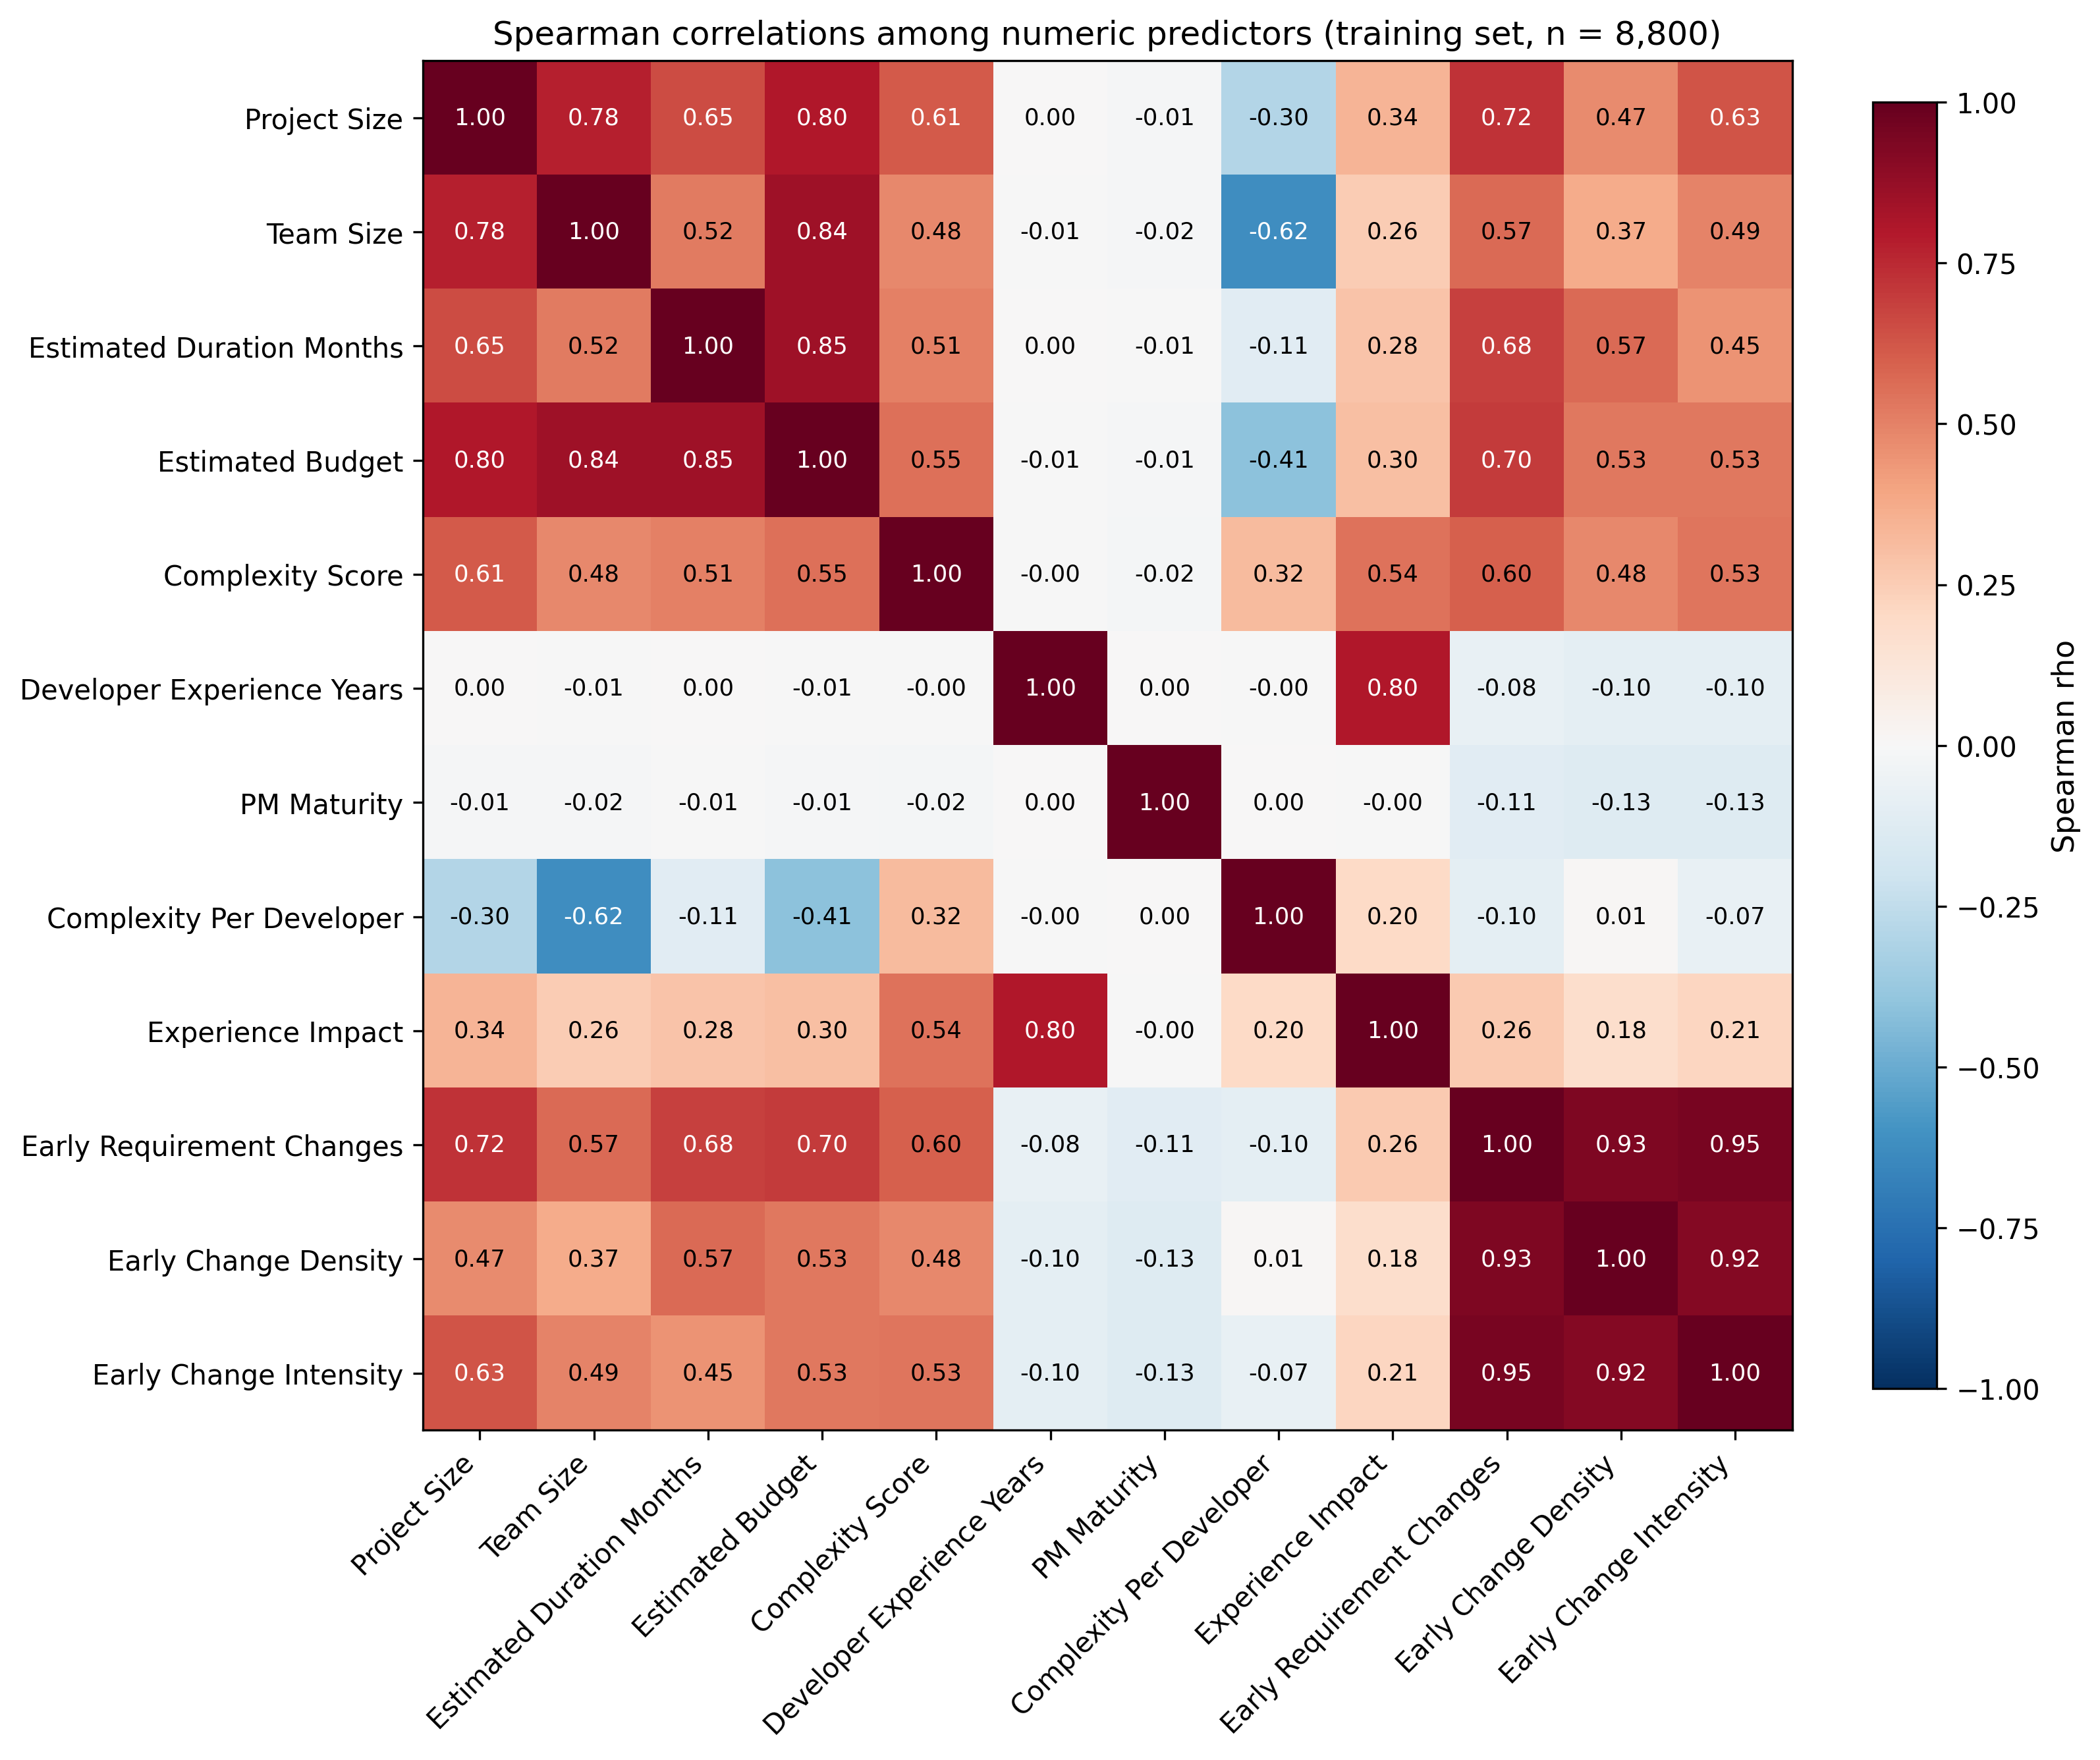

,VIF
Early_Change_Density,15.77
Experience_Impact,14.38
Early_Requirement_Changes,12.72
Early_Change_Intensity,11.02
Developer_Experience_Years,10.24
Estimated_Budget,9.76
Team_Size,9.47
Complexity_Score,8.81
Estimated_Duration_Months,7.92
Project_Size,5.77


In [14]:
display(Image(os.path.join(fig_dir, 'fig2_correlation.png'), width=750))
display(pd.Series(R['vif'], name='VIF').round(2).to_frame())

## 9. Hyperparameter tuning — identical procedure for all five models (Table S2, Table S4)

50-draw randomised search, stratified 5-fold CV on the training set, scored by log loss. This is the slow step.

In [15]:
# ---------------- tuning: identical procedure for all models ----------------
cv = StratifiedKFold(5, shuffle=True, random_state=seed)
zoo = model_zoo(seed)
fitted, cv_rows, tuned = {}, [], {}
for name, (est, scale, space) in zoo.items():
    pipe = Pipeline([("prep", make_preprocessor(FEATURES_CUTOFF, scale)), ("clf", est)])
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="neg_log_loss", cv=cv,
                                random_state=seed, n_jobs=1, refit=True,
                                return_train_score=True)
    search.fit(tr[FEATURES_CUTOFF], y_tr)
    b = search.best_index_
    cvres = search.cv_results_
    fold_auc = []
    best = search.best_estimator_
    # fold-level AUC / accuracy for the selected configuration (refit inside each fold)
    oof = cross_val_predict(clone(best), tr[FEATURES_CUTOFF], y_tr, cv=cv,
                            method="predict_proba")[:, 1]
    for k, (a, v) in enumerate(cv.split(tr, y_tr)):
        fold_auc.append(roc_auc_score(y_tr[v], oof[v]))
    p_train = best.predict_proba(tr[FEATURES_CUTOFF])[:, 1]
    p_test = best.predict_proba(te[FEATURES_CUTOFF])[:, 1]
    fitted[name] = {"model": best, "oof": oof, "p_test": p_test, "p_train": p_train}
    tuned[name] = {k.replace("clf__", ""): (v.item() if hasattr(v, "item") else v)
                   for k, v in search.best_params_.items()}
    cv_rows.append({"Model": name,
                    "CV_logloss_mean": -cvres["mean_test_score"][b],
                    "CV_logloss_sd": cvres["std_test_score"][b],
                    "Train_logloss_in_CV": -cvres["mean_train_score"][b],
                    "OOF_AUC_mean": np.mean(fold_auc), "OOF_AUC_sd": np.std(fold_auc, ddof=1),
                    "Train_AUC_refit": roc_auc_score(y_tr, p_train),
                    "Test_AUC": roc_auc_score(y_te, p_test)})
    print(f"[tuned] {name}: {tuned[name]}")
pd.DataFrame(cv_rows).to_csv(os.path.join(tab_dir, "S_overfitting_cv.csv"), index=False)
R["cv"] = cv_rows
R["tuned_params"] = tuned

[tuned] Logistic Regression: {'C': 0.4205156450913872}
[tuned] Decision Tree: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 136}
[tuned] Random Forest: {'max_depth': 14, 'max_features': 'sqrt', 'min_samples_leaf': 15, 'n_estimators': 306}
[tuned] LightGBM: {'colsample_bytree': 0.7888859700647797, 'learning_rate': 0.014308552498147852, 'min_child_samples': 82, 'n_estimators': 742, 'num_leaves': 8, 'reg_lambda': 0.7707580772445938, 'subsample': 0.6943939678995823, 'subsample_freq': 1}
[tuned] XGBoost: {'colsample_bytree': 0.8066543565084057, 'learning_rate': 0.02184472491888753, 'max_depth': 2, 'min_child_weight': 0.7048979113298943, 'n_estimators': 751, 'reg_alpha': 0.11617448033918634, 'reg_lambda': 5.824688255969172, 'subsample': 0.6754828433365517}


In [16]:
display(pd.DataFrame(R['cv']).round(4))
for m, p in R['tuned_params'].items(): print(f'{m}: {p}')

,Model,CV_logloss_mean,CV_logloss_sd,Train_logloss_in_CV,OOF_AUC_mean,OOF_AUC_sd,Train_AUC_refit,Test_AUC
0,Logistic Regression,0.4245,0.0176,0.4210,0.8704,0.0130,0.8724,0.8828
1,Decision Tree,0.4582,0.0172,0.4446,0.8406,0.0132,0.8483,0.8451
2,Random Forest,0.4296,0.0164,0.3563,0.8657,0.0137,0.9215,0.8718
3,LightGBM,0.4255,0.0189,0.3786,0.8692,0.0140,0.8966,0.8779
4,XGBoost,0.4239,0.0194,0.3996,0.8702,0.0146,0.8842,0.8787


Logistic Regression: {'C': 0.4205156450913872}
Decision Tree: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 136}
Random Forest: {'max_depth': 14, 'max_features': 'sqrt', 'min_samples_leaf': 15, 'n_estimators': 306}
LightGBM: {'colsample_bytree': 0.7888859700647797, 'learning_rate': 0.014308552498147852, 'min_child_samples': 82, 'n_estimators': 742, 'num_leaves': 8, 'reg_lambda': 0.7707580772445938, 'subsample': 0.6943939678995823, 'subsample_freq': 1}
XGBoost: {'colsample_bytree': 0.8066543565084057, 'learning_rate': 0.02184472491888753, 'max_depth': 2, 'min_child_weight': 0.7048979113298943, 'n_estimators': 751, 'reg_alpha': 0.11617448033918634, 'reg_lambda': 5.824688255969172, 'subsample': 0.6754828433365517}


## 10. Test-set metrics recomputed from confusion matrices (Tables 3–4)

In [17]:
# ---------------- thresholds and test metrics ----------------
rows = []
for name, d in fitted.items():
    m = metrics_from_cm(y_te, d["p_test"], 0.5)
    m["Model"] = name
    rows.append(m)
comp = pd.DataFrame(rows).set_index("Model")
comp.to_csv(os.path.join(tab_dir, "table4_model_comparison.csv"))
R["comparison_t050"] = comp.reset_index().to_dict(orient="records")

# bootstrap CIs for XGBoost test metrics
xg = fitted["XGBoost"]
rng = np.random.default_rng(seed)
boots = {k: [] for k in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "Brier"]}
for _ in range(2000):
    i = rng.integers(0, len(y_te), len(y_te))
    yy, pp = y_te[i], xg["p_test"][i]
    pr = (pp >= 0.5).astype(int)
    boots["Accuracy"].append(accuracy_score(yy, pr))
    boots["Precision"].append(precision_score(yy, pr, zero_division=0))
    boots["Recall"].append(recall_score(yy, pr))
    boots["F1"].append(f1_score(yy, pr))
    boots["ROC_AUC"].append(roc_auc_score(yy, pp))
    boots["Brier"].append(brier_score_loss(yy, pp))
R["xgb_test_ci"] = {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
                    for k, v in boots.items()}

# recall-oriented threshold chosen on OUT-OF-FOLD training predictions only
target_recall = 0.90
fpr, tpr, thr = roc_curve(y_tr, xg["oof"])
ok = np.where(tpr >= target_recall)[0][0]
thr_rec = float(thr[ok])
R["xgb_t050"] = metrics_from_cm(y_te, xg["p_test"], 0.5)
R["xgb_trecall"] = metrics_from_cm(y_te, xg["p_test"], thr_rec)
R["xgb_recall_threshold"] = thr_rec
R["xgb_train_metrics_t050"] = metrics_from_cm(y_tr, xg["p_train"], 0.5)
R["xgb_oof_metrics_t050"] = metrics_from_cm(y_tr, xg["oof"], 0.5)

In [18]:
display(pd.read_csv(os.path.join(tab_dir, 'table4_model_comparison.csv')).round(3))
print('XGBoost 95% bootstrap CIs:', {k: tuple(round(x, 3) for x in v) for k, v in R['xgb_test_ci'].items()})
print('Recall-oriented threshold (from out-of-fold training predictions):', round(R['xgb_recall_threshold'], 3))
display(pd.DataFrame([R['xgb_t050'], R['xgb_trecall']], index=['threshold 0.50', 'recall-oriented']).round(3))

,Model,threshold,TP,FN,FP,TN,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC,Brier,LogLoss
0,Logistic Regression,0.5,531,285,120,1264,0.816,0.816,0.651,0.724,0.913,0.883,0.130,0.407
1,Decision Tree,0.5,494,322,119,1265,0.800,0.806,0.605,0.691,0.914,0.845,0.144,0.449
2,Random Forest,0.5,528,288,127,1257,0.811,0.806,0.647,0.718,0.908,0.872,0.135,0.422
3,LightGBM,0.5,549,267,138,1246,0.816,0.799,0.673,0.731,0.900,0.878,0.132,0.412
4,XGBoost,0.5,550,266,136,1248,0.817,0.802,0.674,0.732,0.902,0.879,0.131,0.411


XGBoost 95% bootstrap CIs: {'Accuracy': (0.801, 0.833), 'Precision': (0.77, 0.831), 'Recall': (0.641, 0.706), 'F1': (0.705, 0.757), 'ROC_AUC': (0.863, 0.893), 'Brier': (0.123, 0.14)}
Recall-oriented threshold (from out-of-fold training predictions): 0.186


,threshold,TP,FN,FP,TN,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC,Brier,LogLoss
threshold 0.50,0.500,550,266,136,1248,0.817,0.802,0.674,0.732,0.902,0.879,0.131,0.411
recall-oriented,0.186,740,76,551,833,0.715,0.573,0.907,0.702,0.602,0.879,0.131,0.411


## 11. ROC curves and calibration (Figure 3)

In [19]:
# ---------------- calibration + ROC figure ----------------
p = xg["p_test"]
R["xgb_brier"] = float(brier_score_loss(y_te, p))
R["brier_reference_prevalence"] = float(brier_score_loss(y_te, np.full_like(p, y_tr.mean())))
R["brier_skill"] = 1 - R["xgb_brier"] / R["brier_reference_prevalence"]
R["xgb_ece"] = float(expected_calibration_error(y_te, p))
frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
pd.DataFrame({"mean_predicted": mean_pred, "observed_fraction": frac_pos}).to_csv(
    os.path.join(tab_dir, "S_reliability_bins.csv"), index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for name, d in fitted.items():
    f_, t_, _ = roc_curve(y_te, d["p_test"])
    axes[0].plot(f_, t_, lw=2 if name == "XGBoost" else 1.2,
                 label=f"{name} (AUC {roc_auc_score(y_te, d['p_test']):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate")
axes[0].set_title("(a) ROC curves, held-out test set"); axes[0].legend(loc="lower right")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8, label="Perfect calibration")
axes[1].plot(mean_pred, frac_pos, "o-", color="#1f4e9c", lw=2, label="XGBoost (10 quantile bins)")
axes[1].set_xlabel("Mean predicted probability"); axes[1].set_ylabel("Observed fraction high volatility")
axes[1].set_title(f"(b) Reliability, test set (Brier {R['xgb_brier']:.3f}, ECE {R['xgb_ece']:.3f})")
axes[1].legend(loc="upper left")
ax2 = axes[1].inset_axes([0.58, 0.08, 0.38, 0.25])
ax2.hist(p, bins=30, color="#999999"); ax2.set_yticks([]); ax2.set_title("predicted p", fontsize=9)
ax2.tick_params(labelsize=8)
fig.tight_layout(); fig.savefig(os.path.join(fig_dir, "fig3_roc_calibration.png"), bbox_inches="tight")
plt.close(fig)

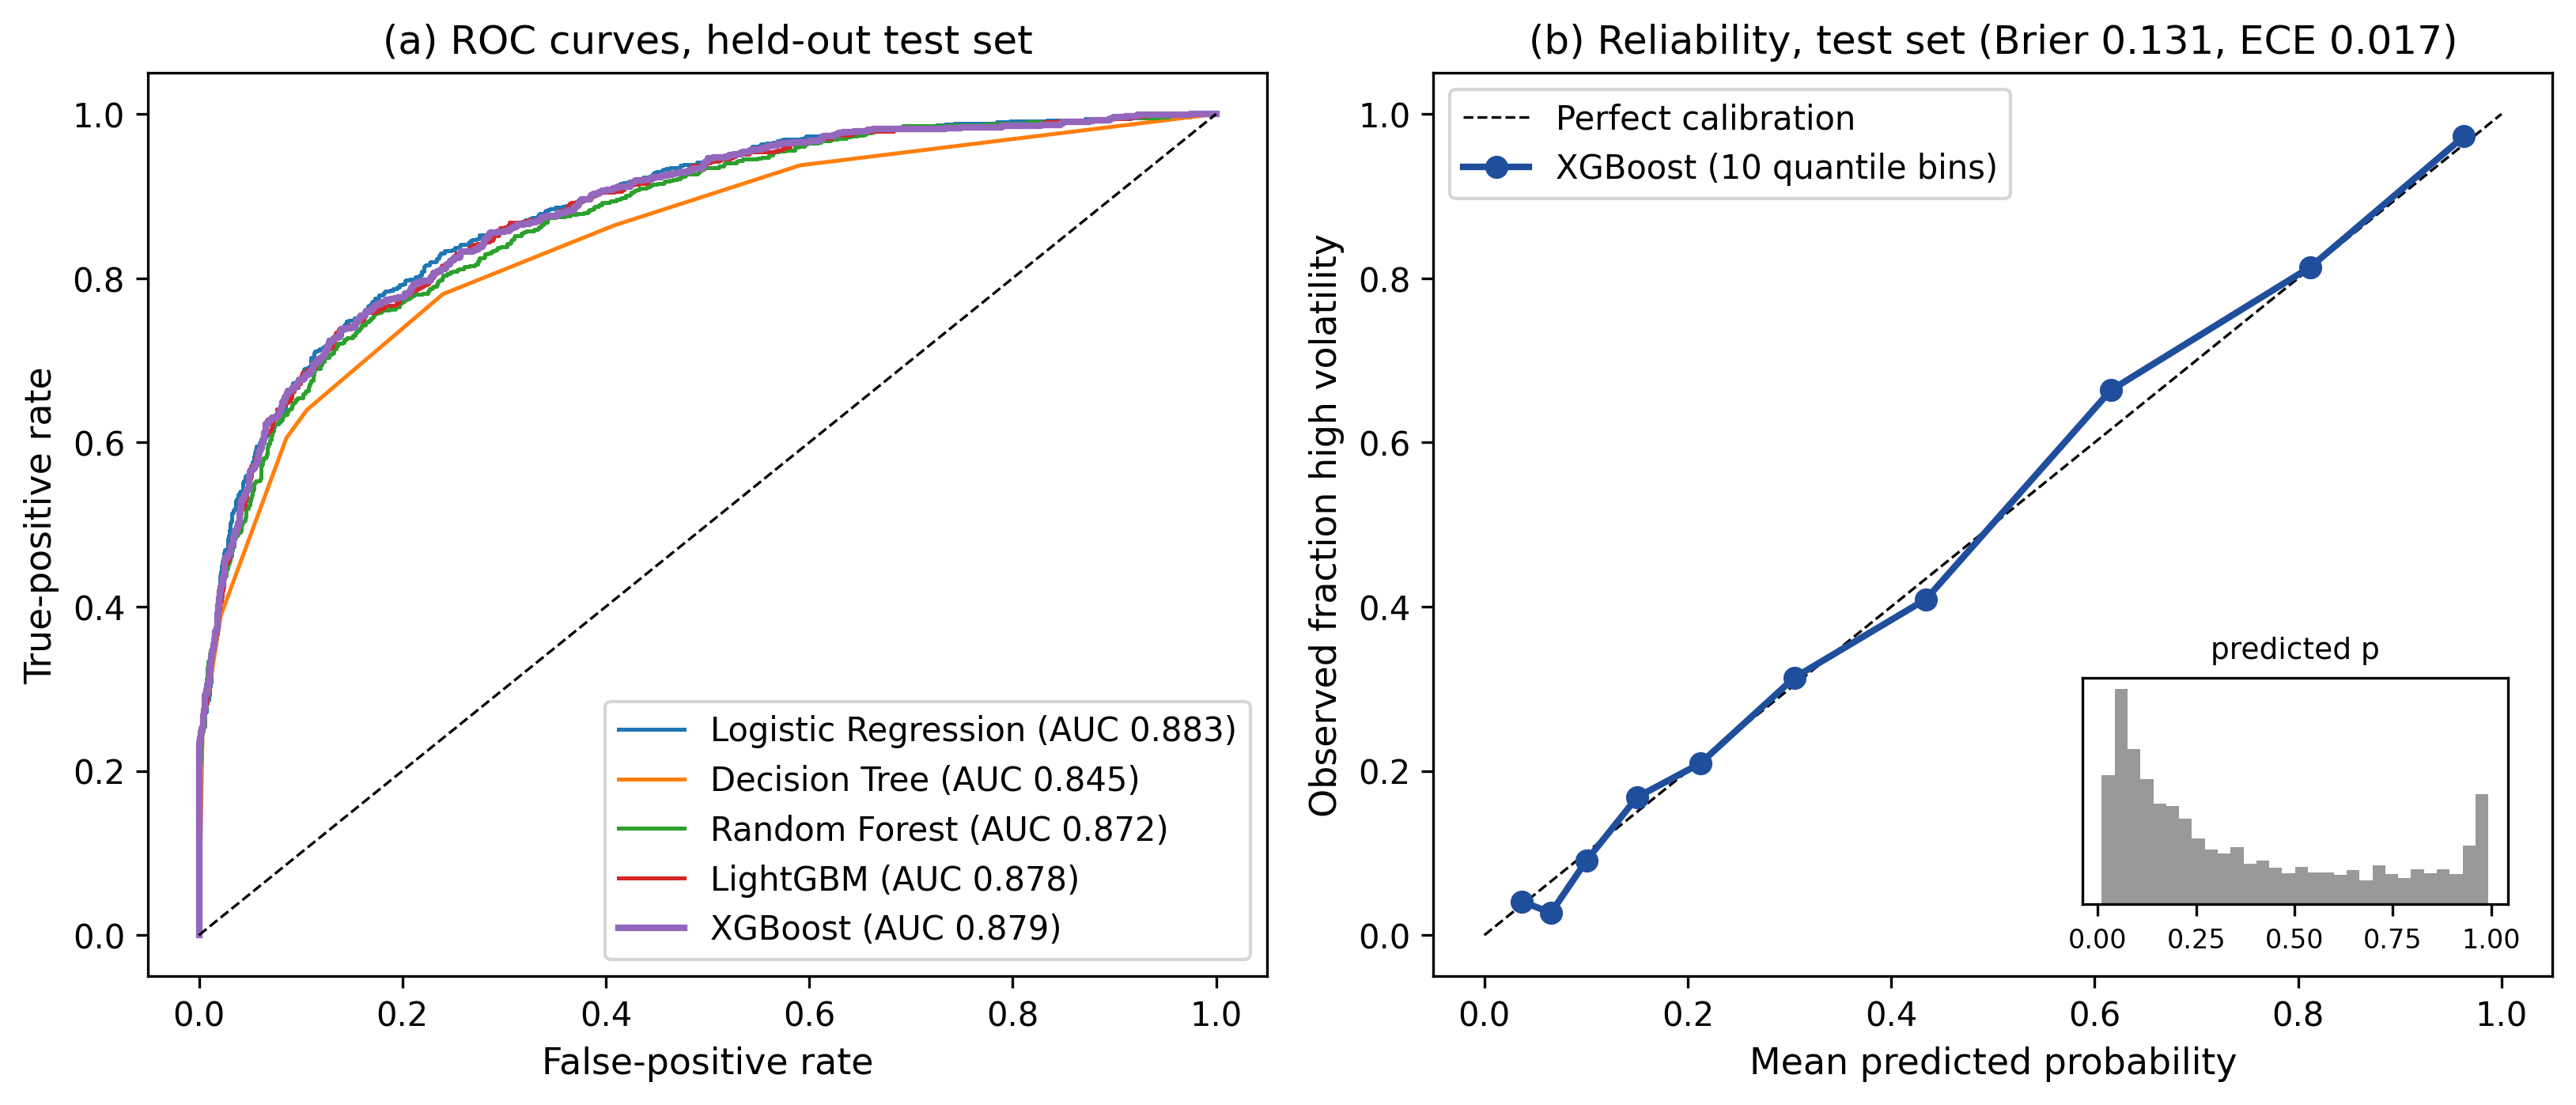

Brier 0.131 vs prevalence reference 0.233 -> skill 0.437; ECE 0.017


In [20]:
display(Image(os.path.join(fig_dir, 'fig3_roc_calibration.png'), width=900))
print(f"Brier {R['xgb_brier']:.3f} vs prevalence reference {R['brier_reference_prevalence']:.3f} -> skill {R['brier_skill']:.3f}; ECE {R['xgb_ece']:.3f}")

## 12. Gain vs SHAP importance, SHAP summary and waterfall (Figures 4–6, Figure S1)

SHAP values are on the **log-odds** scale of the high-volatility class; the code asserts that the baseline plus the SHAP values reproduces the model's log-odds.

In [21]:
# ---------------- importance: gain vs mean |SHAP| ----------------
prep = xg["model"].named_steps["prep"]
booster_model = xg["model"].named_steps["clf"]
X_te_enc = pd.DataFrame(prep.transform(te[FEATURES_CUTOFF]), columns=prep.get_feature_names_out())
explainer = shap.TreeExplainer(booster_model, model_output="raw")   # raw = log-odds margin
sv = explainer(X_te_enc)
base = float(np.atleast_1d(explainer.expected_value)[0])
# additivity check: base + sum(SHAP) == model log-odds
margin = booster_model.predict(X_te_enc, output_margin=True)
assert np.allclose(base + sv.values.sum(1), margin, atol=1e-3)
R["shap_base_logodds"] = base
R["shap_base_prob"] = float(1 / (1 + np.exp(-base)))

def group_of(col):
    for g in NOMINAL:
        if col.startswith(g + "_"):
            return g
    return col
groups = [group_of(c) for c in X_te_enc.columns]
shap_grouped = pd.DataFrame(sv.values, columns=X_te_enc.columns).T.groupby(groups).sum().T
mean_abs = shap_grouped.abs().mean().sort_values(ascending=False)
gain = pd.Series(booster_model.get_booster().get_score(importance_type="total_gain"))
gain = gain.reindex(X_te_enc.columns).fillna(0).groupby(groups).sum()
gain = (gain / gain.sum()).sort_values(ascending=False)
imp = pd.DataFrame({"mean_abs_SHAP_logodds": mean_abs, "total_gain_share": gain})
imp["rank_SHAP"] = imp["mean_abs_SHAP_logodds"].rank(ascending=False).astype(int)
imp["rank_gain"] = imp["total_gain_share"].rank(ascending=False).astype(int)
imp.sort_values("rank_SHAP").to_csv(os.path.join(tab_dir, "S_importance_gain_vs_shap.csv"))
R["importance"] = imp.sort_values("rank_SHAP").reset_index().rename(
    columns={"index": "feature"}).to_dict(orient="records")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
g = gain.sort_values()
axes[0].barh([s.replace("_", " ") for s in g.index], g.values, color="#7f7f7f")
axes[0].set_xlabel("Share of total split gain (XGBoost 'total_gain')")
axes[0].set_title("(a) Gain-based importance")
s_ = mean_abs.sort_values()
axes[1].barh([s.replace("_", " ") for s in s_.index], s_.values, color="#1f4e9c")
axes[1].set_xlabel("Mean |SHAP value| (log-odds), test set")
axes[1].set_title("(b) Mean absolute SHAP importance")
fig.tight_layout(); fig.savefig(os.path.join(fig_dir, "fig4_importance.png"), bbox_inches="tight")
plt.close(fig)

# SHAP beeswarm on numeric + ordinal features (one-hot groups summarised in Fig 4b)
keep = [c for c in X_te_enc.columns if group_of(c) == c]
sv_keep = shap.Explanation(values=sv.values[:, [X_te_enc.columns.get_loc(c) for c in keep]],
                           base_values=sv.base_values, data=X_te_enc[keep].values,
                           feature_names=[c.replace("_", " ") for c in keep])
plt.figure()
shap.plots.beeswarm(sv_keep, max_display=len(keep), show=False, plot_size=(9, 6.5))
plt.xlabel("SHAP value (impact on log-odds of HIGH later-phase volatility)")
plt.title("SHAP summary, held-out test set (class explained: High_Volatility = 1)", fontsize=11)
plt.savefig(os.path.join(fig_dir, "fig5_shap_beeswarm.png"), bbox_inches="tight"); plt.close("all")

# direction checks used in the text (Spearman between feature value and its SHAP value)
direction = {}
for c in keep:
    rho = stats.spearmanr(X_te_enc[c], sv.values[:, X_te_enc.columns.get_loc(c)]).statistic
    direction[c] = float(rho)
R["shap_direction_spearman"] = direction

# SHAP dependence for duration (H2 needs explicit check)
j = X_te_enc.columns.get_loc("Estimated_Duration_Months")
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(X_te_enc["Estimated_Duration_Months"], sv.values[:, j], s=6, alpha=0.4, color="#1f4e9c")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Estimated duration (months)"); ax.set_ylabel("SHAP value (log-odds)")
ax.set_title("SHAP dependence: estimated duration")
fig.tight_layout(); fig.savefig(os.path.join(fig_dir, "figS_shap_dependence_duration.png")); plt.close(fig)

# waterfall for one documented test project (closest to the median of the High band)
bands_te = risk_band(p)
cand = np.where(np.asarray(bands_te) == "High")[0]
pick = int(cand[np.argmin(np.abs(p[cand] - np.median(p[cand])))])
ex = shap.Explanation(values=sv.values[pick], base_values=base, data=X_te_enc.iloc[pick].values,
                      feature_names=[c.replace("_", " ") for c in X_te_enc.columns])
plt.figure()
shap.plots.waterfall(ex, max_display=10, show=False)
fx = base + sv.values[pick].sum()
plt.title(f"Test project #{int(te.Project_ID[pick])}: f(x) = {fx:.3f} log-odds "
          f"-> p = {1/(1+np.exp(-fx)):.3f};  E[f(X)] = {base:.3f} log-odds -> p = {1/(1+np.exp(-base)):.3f}",
          fontsize=10)
plt.gcf().set_size_inches(10, 6)
plt.savefig(os.path.join(fig_dir, "fig6_shap_waterfall.png"), bbox_inches="tight"); plt.close("all")
proj = te.iloc[pick]
R["waterfall_project"] = {
    "Project_ID": int(proj.Project_ID), "fx_logodds": float(fx), "p": float(1 / (1 + np.exp(-fx))),
    "model_predict_proba": float(p[pick]), "actual_label": int(proj.High_Volatility),
    "RVI_post": float(proj.RVI_post),
    "inputs": {c: (proj[c].item() if hasattr(proj[c], "item") else proj[c])
               for c in FEATURES_CUTOFF + ["Cutoff_Months"]},
    "check_complexity_per_dev": float(proj.Complexity_Score / proj.Team_Size),
    "check_intensity": float(proj.Early_Requirement_Changes / proj.Cutoff_Months),
    "check_density": float(100 * proj.Early_Requirement_Changes / proj.Project_Size),
    "top_contributions": sorted(
        [(c, float(v)) for c, v in zip(X_te_enc.columns, sv.values[pick])],
        key=lambda t: -abs(t[1]))[:10]}

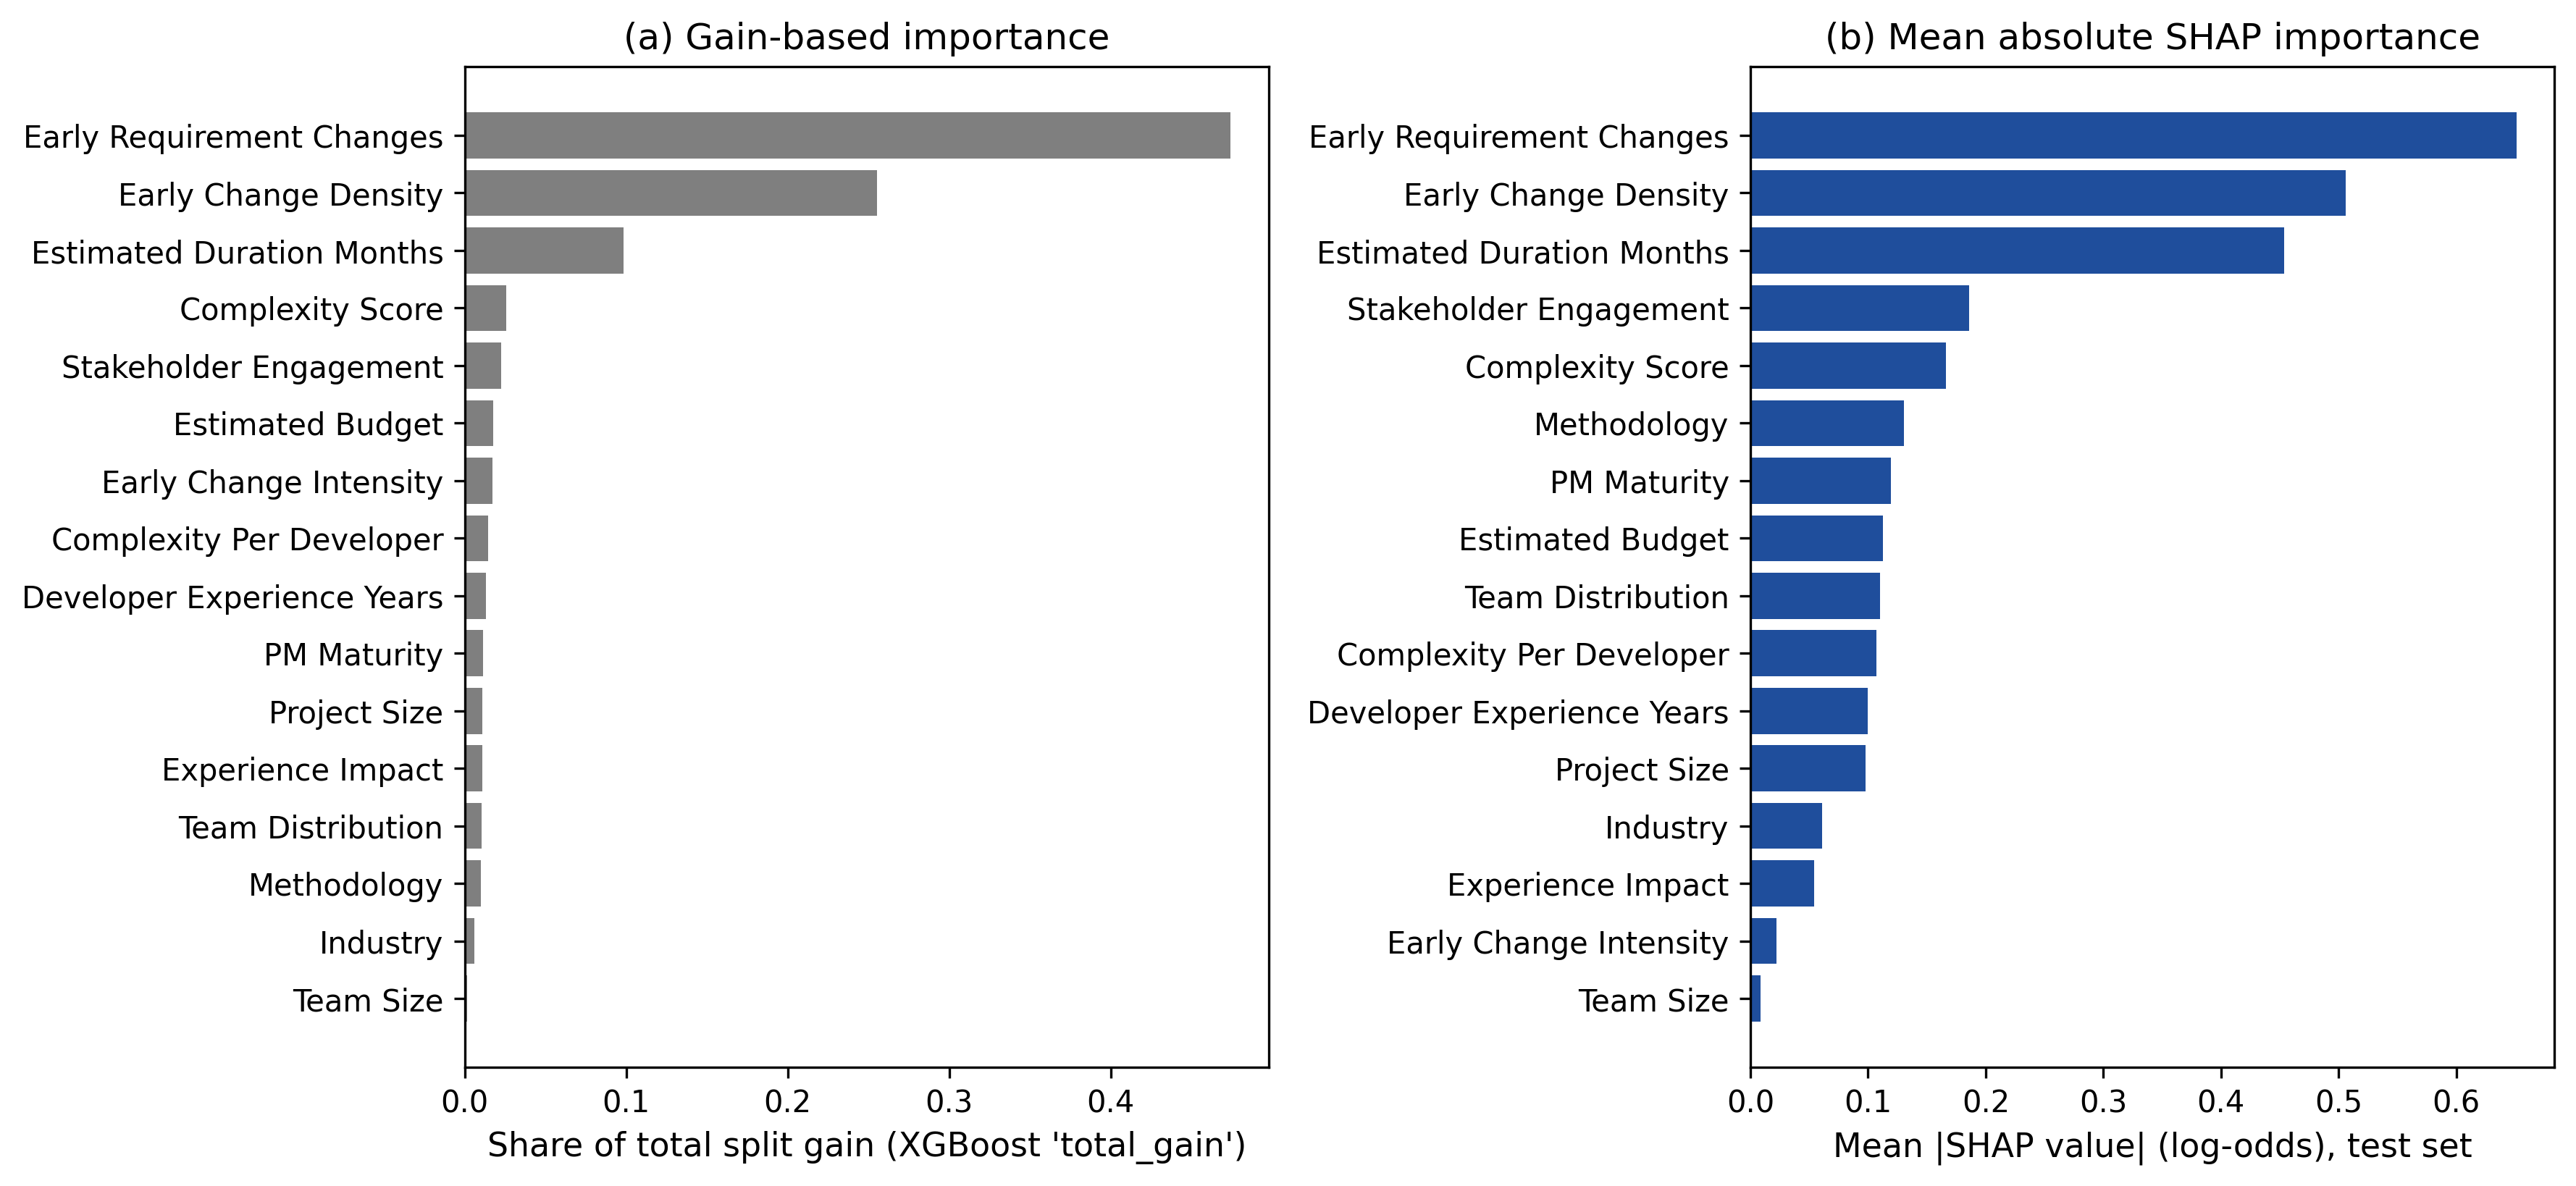

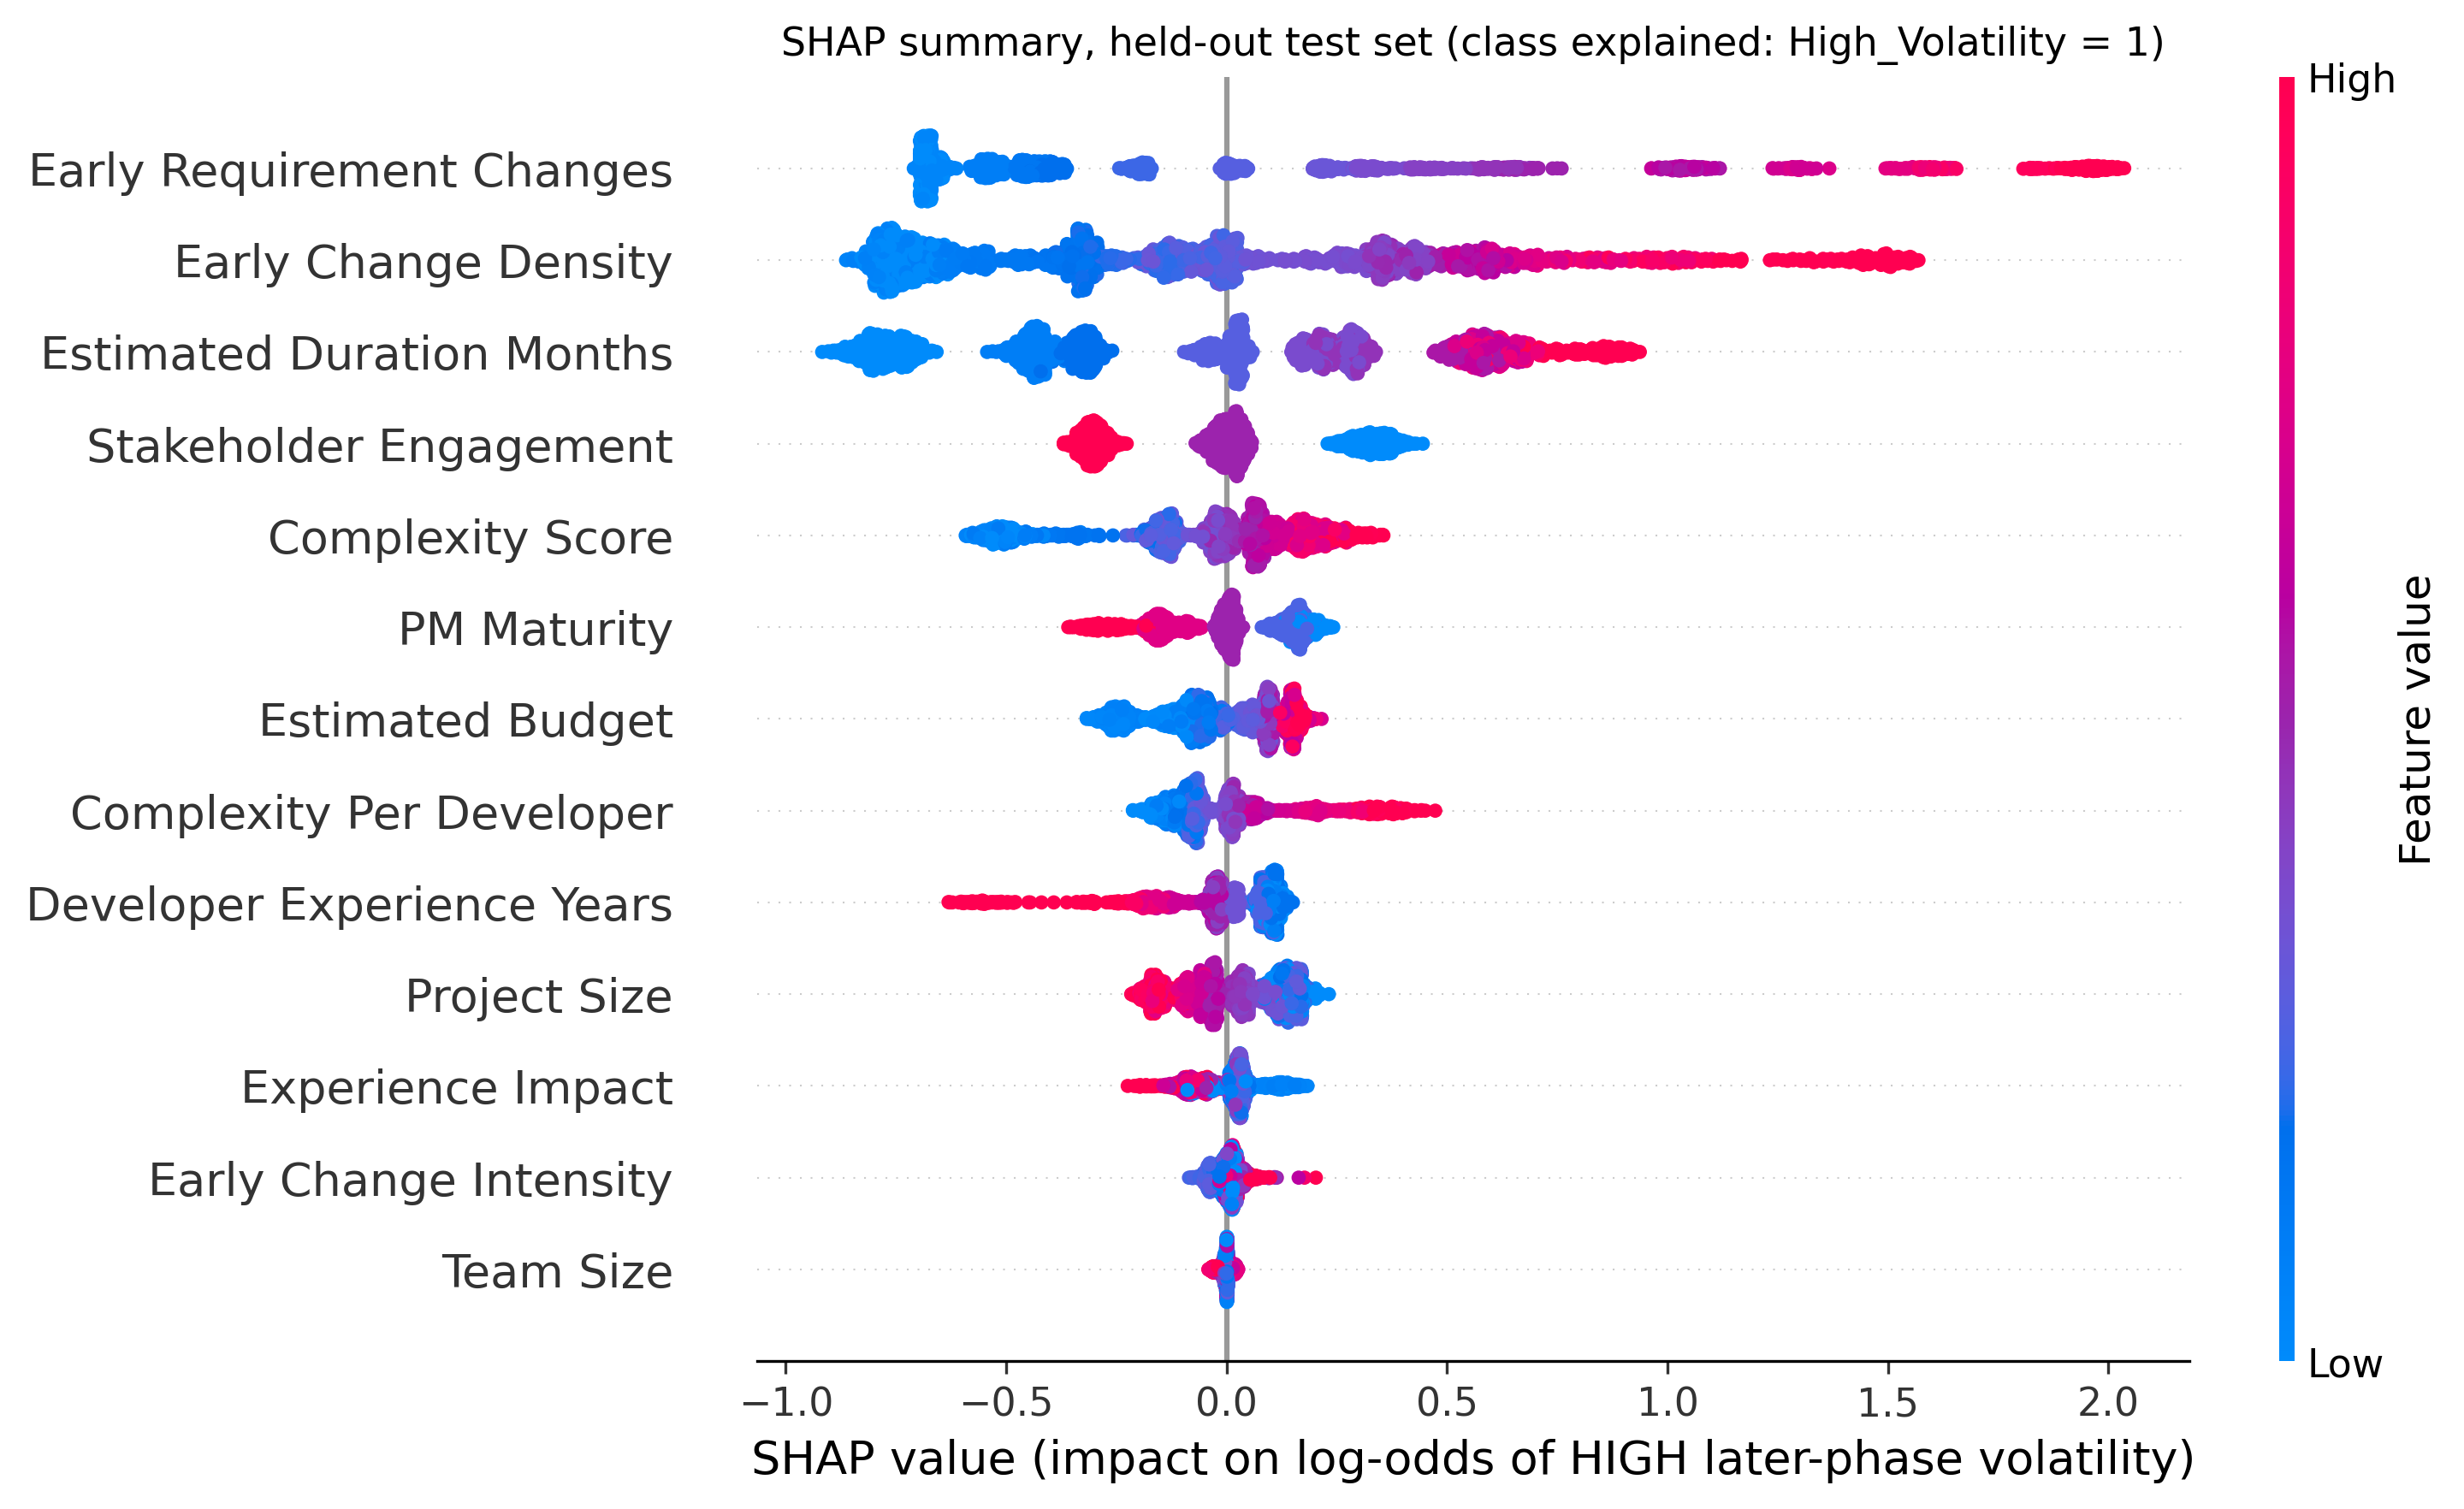

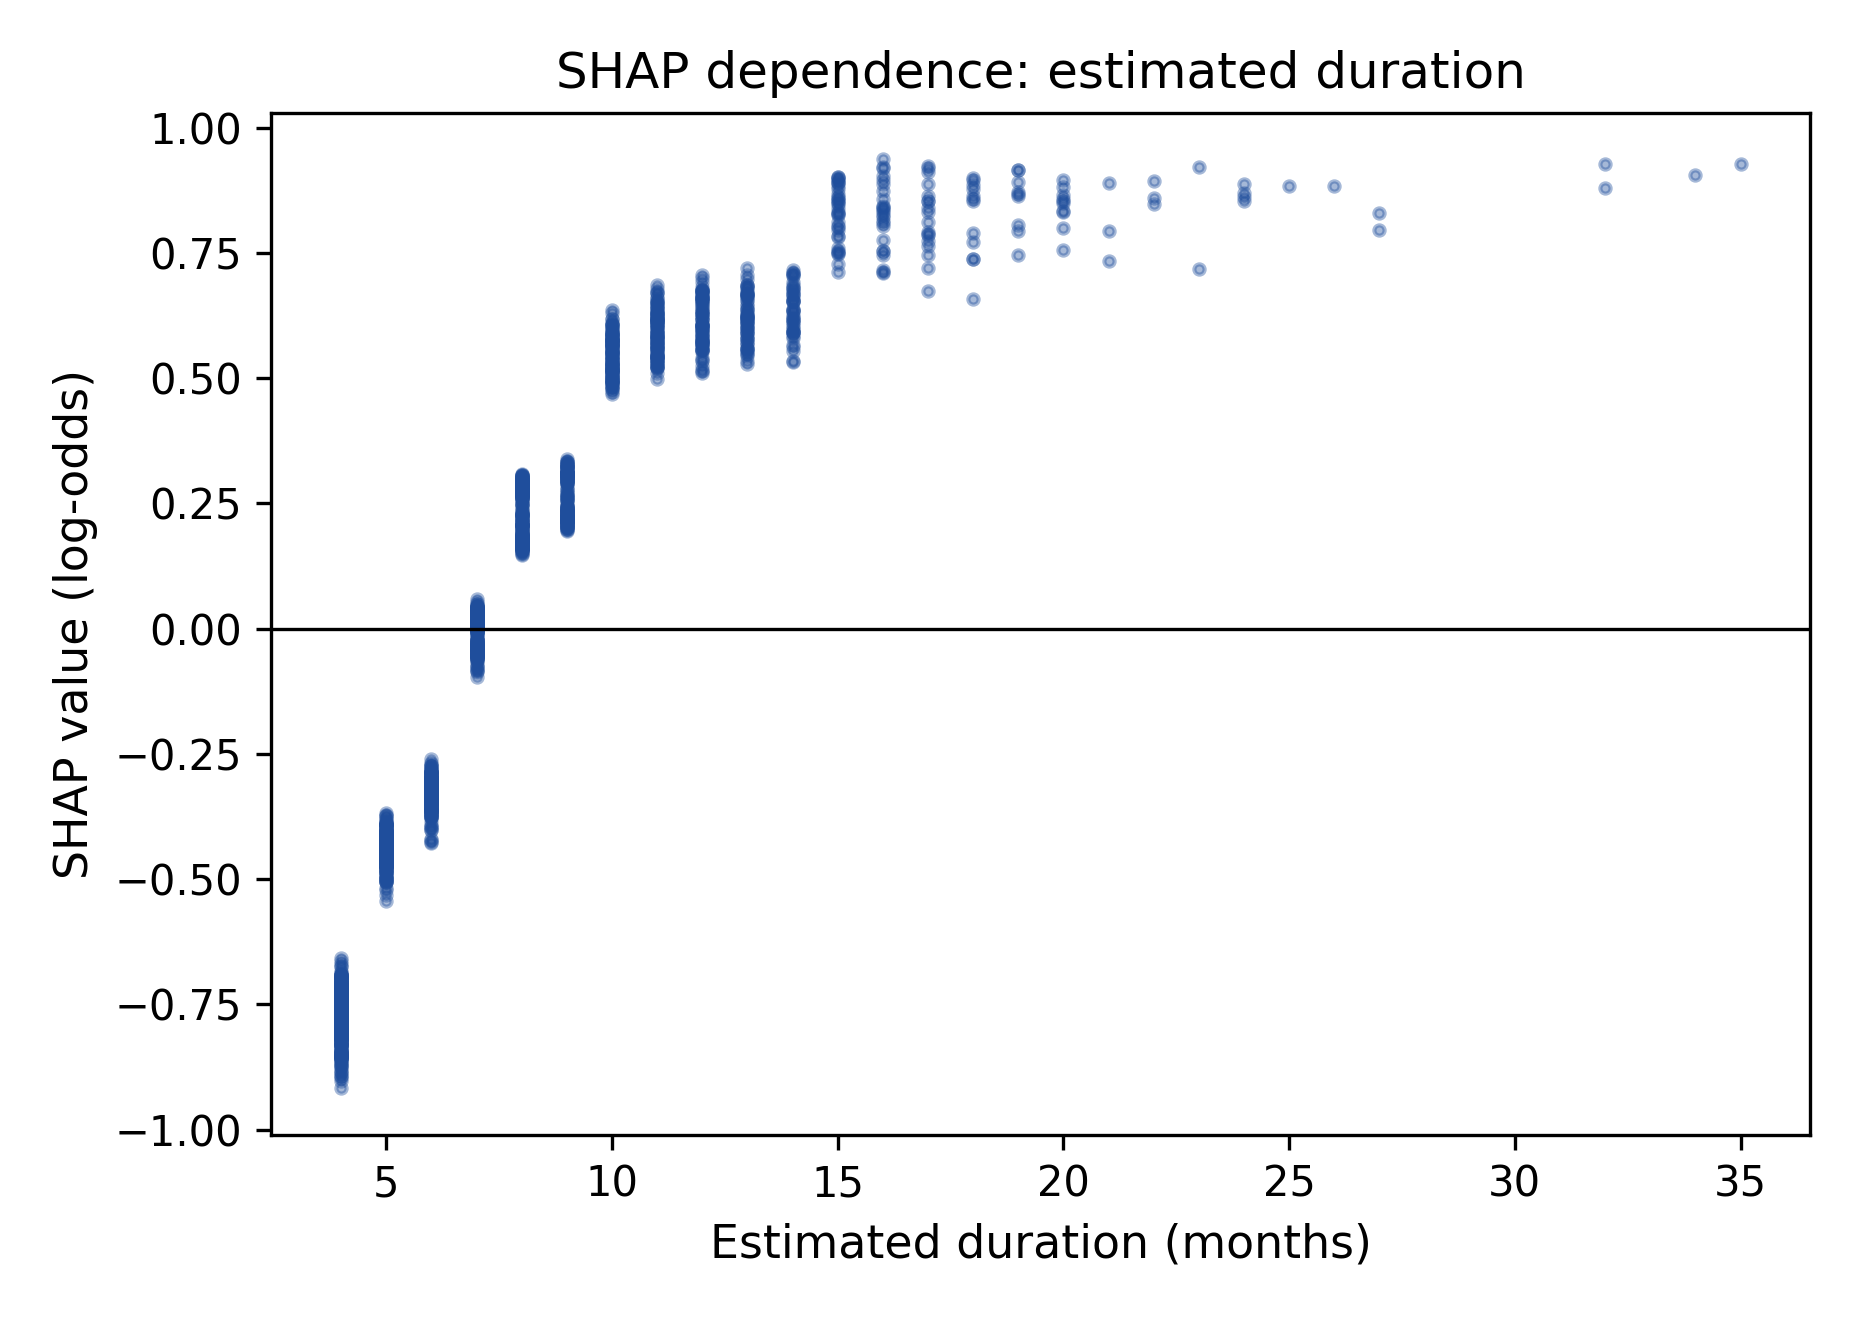

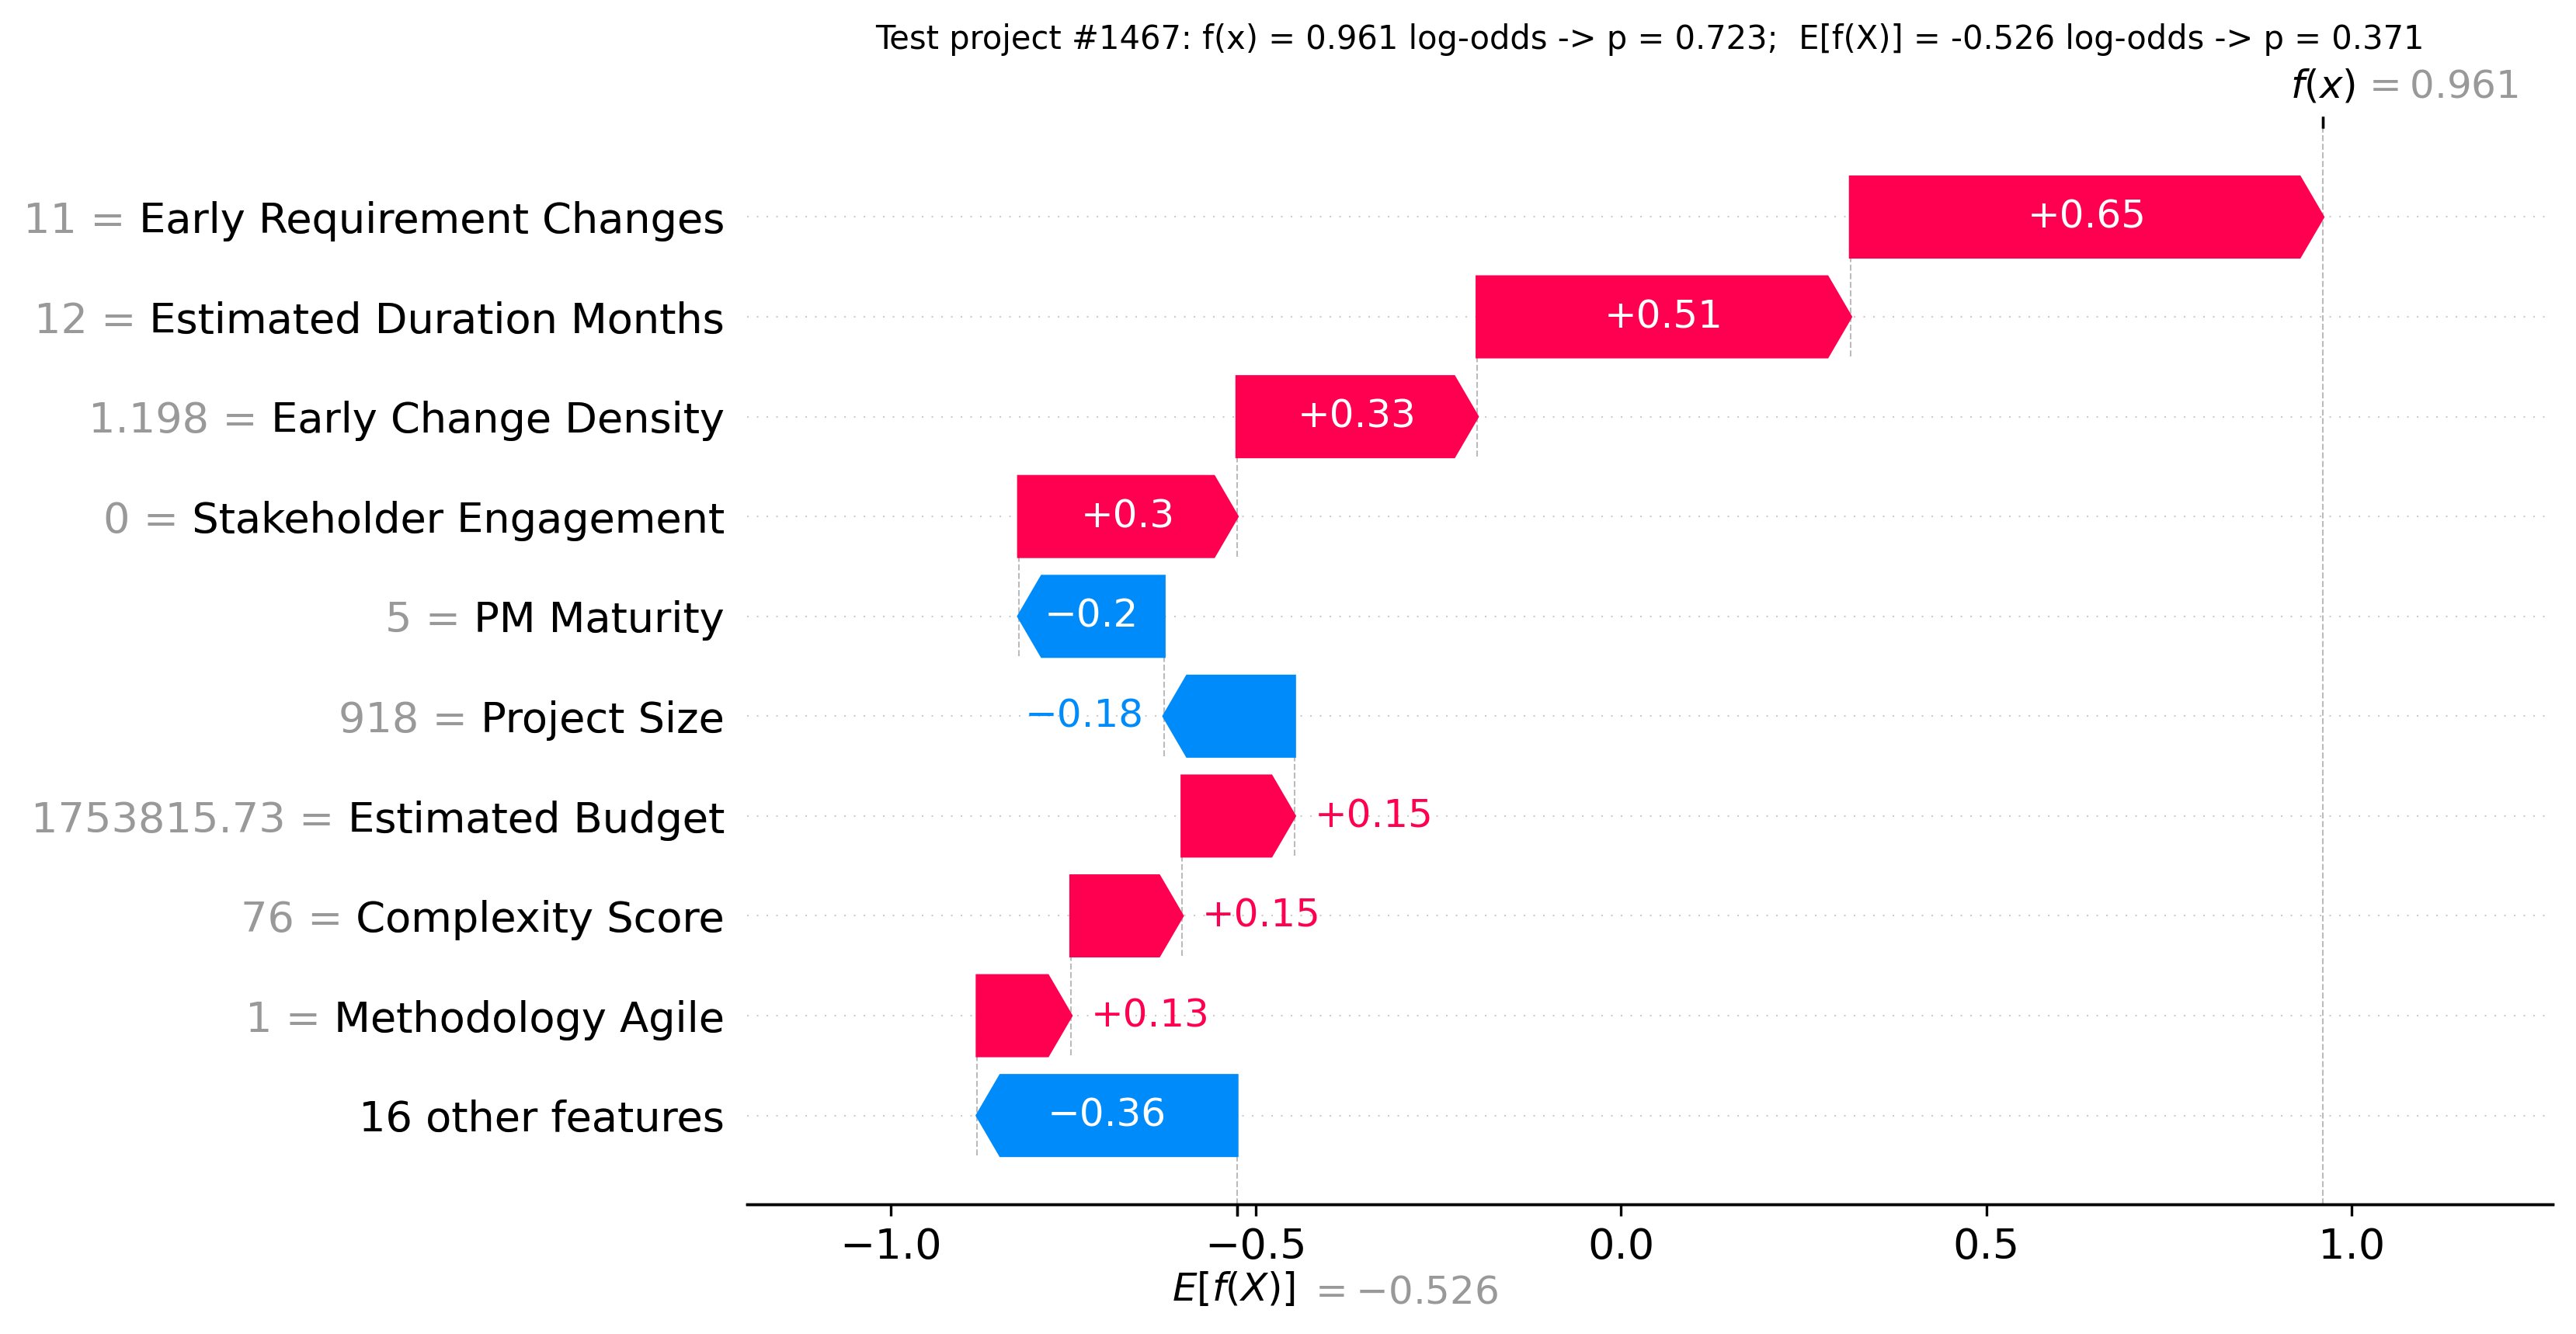

Project 1467: f(x) = 0.961 log-odds -> p = 0.723 (predict_proba 0.723); actual = 1, RVI_post = 5.23
Formula checks: 1.198 3.667 4.471


In [22]:
display(Image(os.path.join(fig_dir, 'fig4_importance.png'), width=900))
display(Image(os.path.join(fig_dir, 'fig5_shap_beeswarm.png'), width=750))
display(Image(os.path.join(fig_dir, 'figS_shap_dependence_duration.png'), width=500))
display(Image(os.path.join(fig_dir, 'fig6_shap_waterfall.png'), width=900))
w = R['waterfall_project']
print(f"Project {w['Project_ID']}: f(x) = {w['fx_logodds']:.3f} log-odds -> p = {w['p']:.3f} (predict_proba {w['model_predict_proba']:.3f}); actual = {w['actual_label']}, RVI_post = {w['RVI_post']:.2f}")
print('Formula checks:', round(w['check_density'], 3), round(w['check_intensity'], 3), round(w['check_complexity_per_dev'], 3))

## 13. Risk bands on the held-out test set (Figure 7)

In [23]:
# ---------------- risk bands on the TEST SET ONLY ----------------
bt = pd.DataFrame({"band": bands_te, "y": y_te, "p": p})
band_tab = bt.groupby("band", observed=False).agg(n=("y", "size"), observed_high_rate=("y", "mean"),
                                                  mean_p=("p", "mean"))
band_tab["percent"] = 100 * band_tab["n"] / len(bt)
band_tab.to_csv(os.path.join(tab_dir, "table5_risk_bands_test.csv"))
R["risk_bands_test"] = band_tab.reset_index().to_dict(orient="records")
plot_risk_bands(p, band_tab, os.path.join(fig_dir, "fig7_risk_bands.png"))

,band,n,observed_high_rate,mean_p,percent
0,Low,1201,0.127,0.127,54.591
1,Moderate,434,0.417,0.433,19.727
2,High,273,0.758,0.725,12.409
3,Critical,292,0.942,0.942,13.273


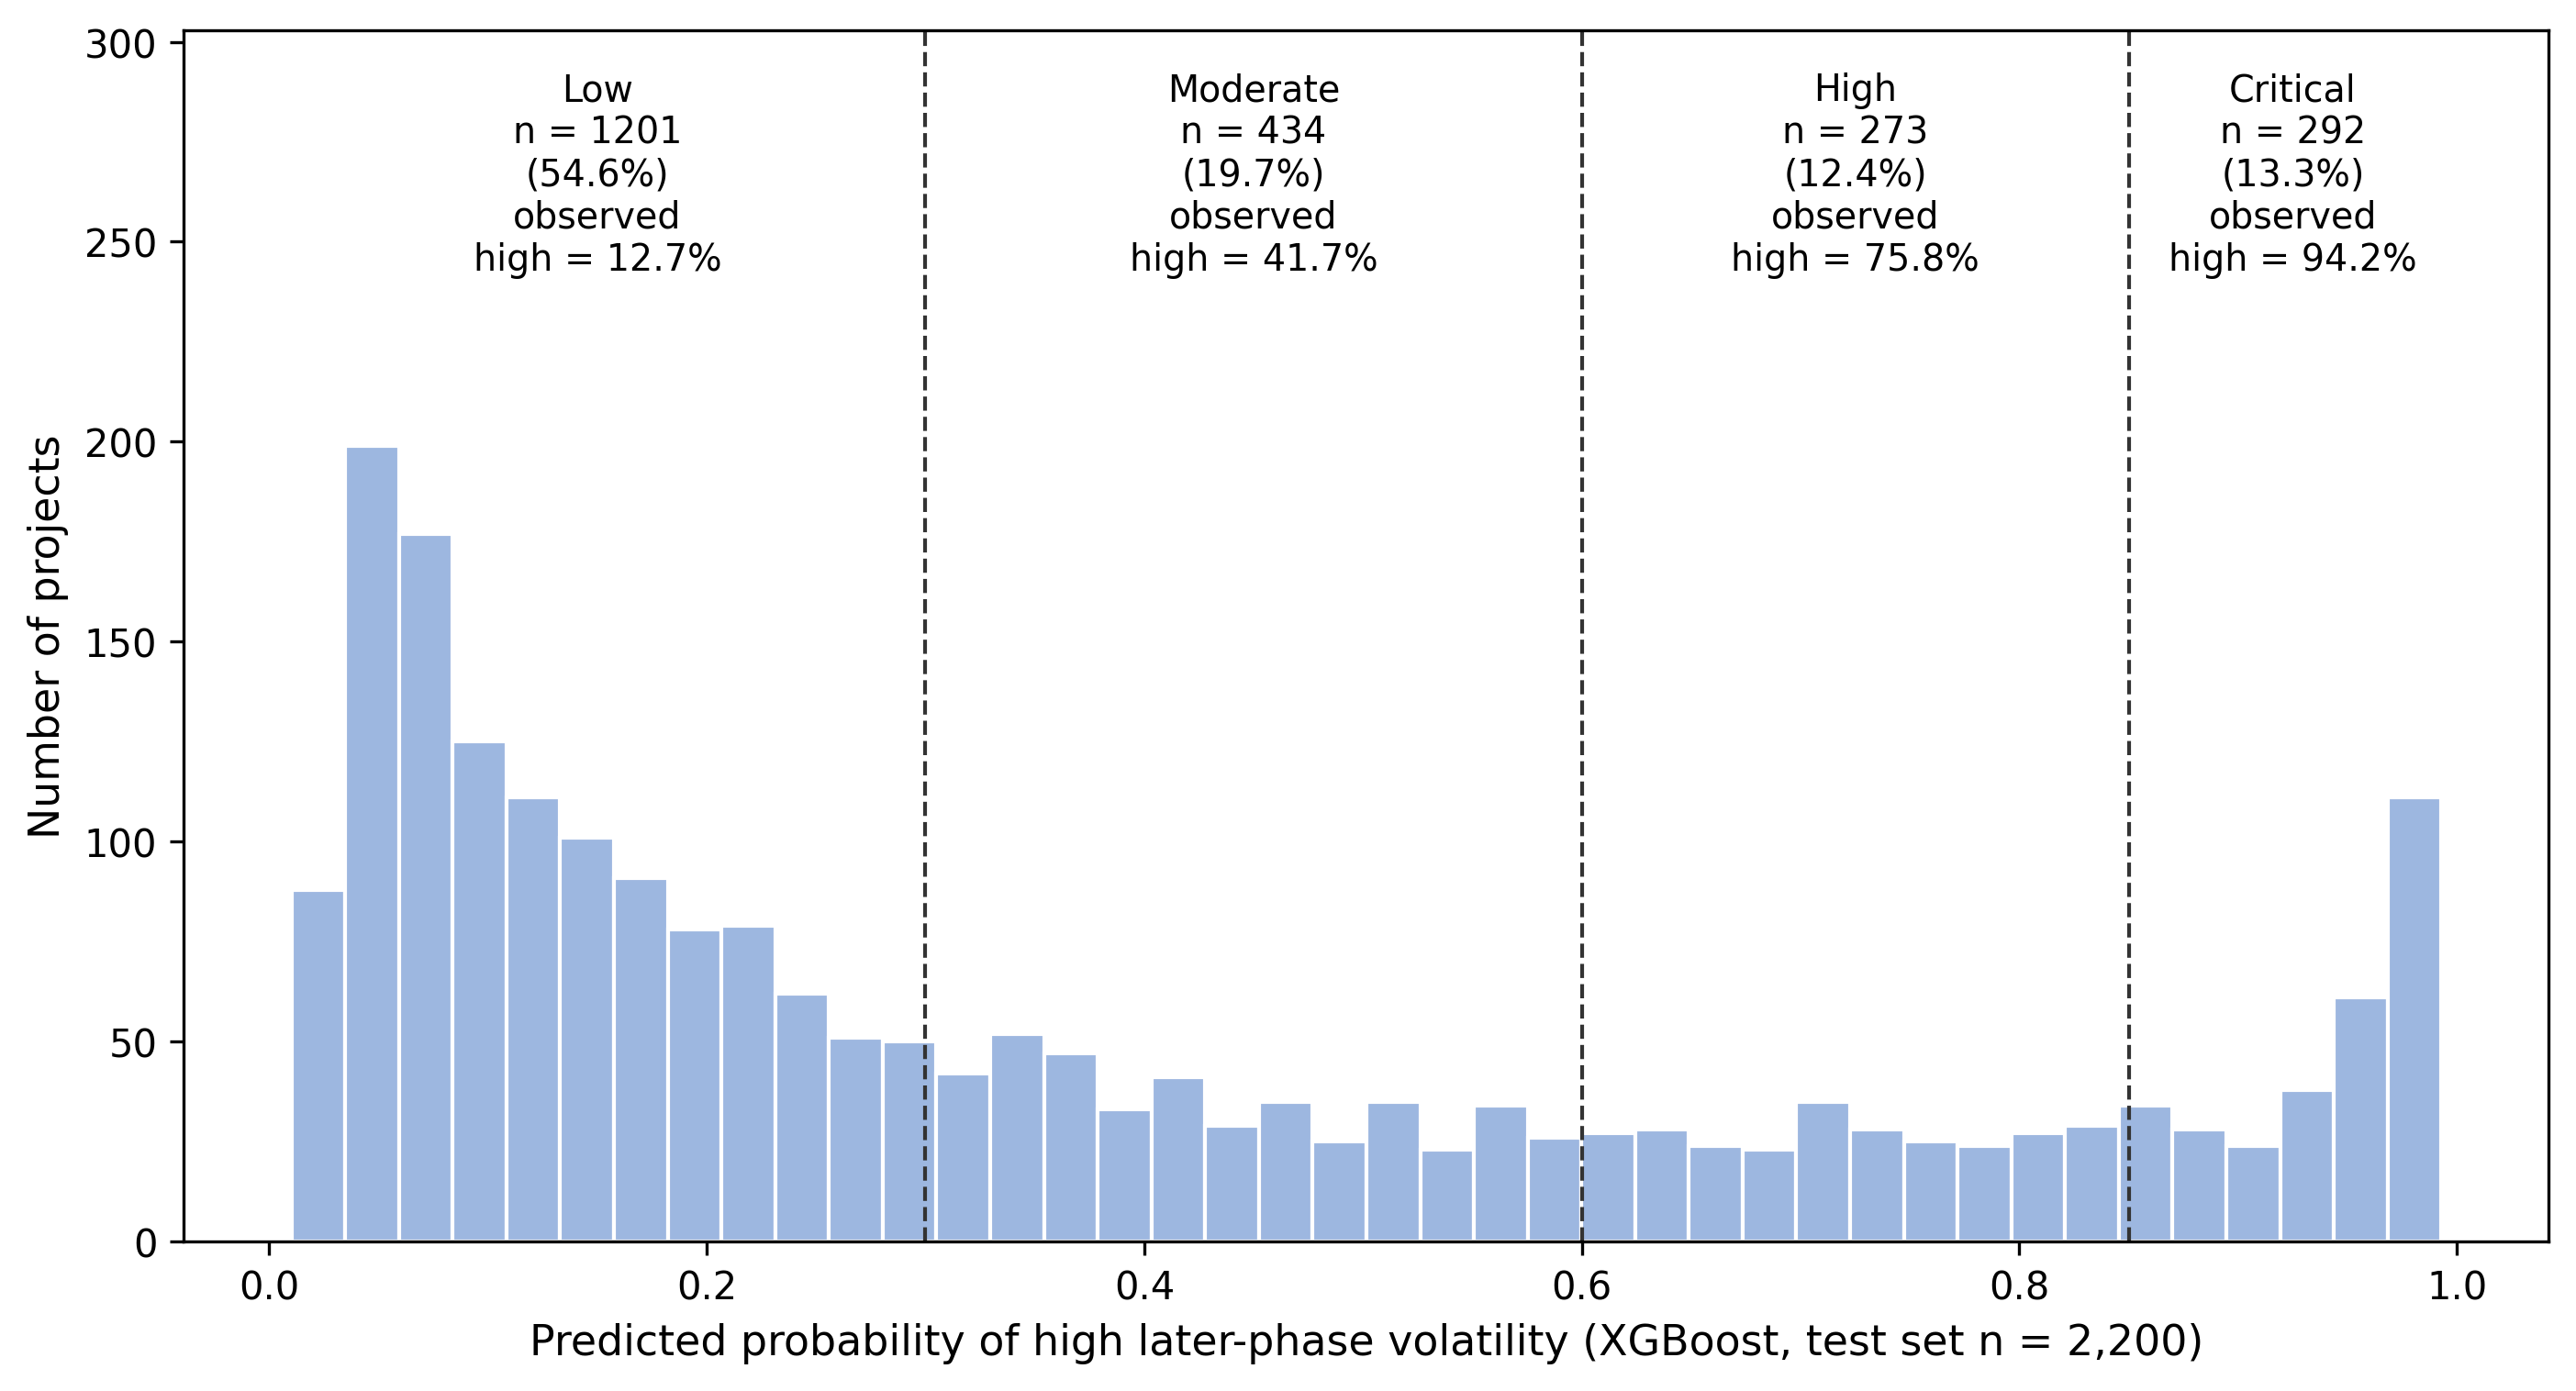

In [24]:
display(pd.read_csv(os.path.join(tab_dir, 'table5_risk_bands_test.csv')).round(3))
display(Image(os.path.join(fig_dir, 'fig7_risk_bands.png'), width=800))

## 14. Ablation with paired bootstrap intervals (Table 5)

In [25]:
# ---------------- ablation (H3 / prediction-time) ----------------
xgb_params = {k: v for k, v in tuned["XGBoost"].items()}
def fit_xgb(features, data_tr, data_te, s):
    pipe = Pipeline([("prep", make_preprocessor(features, False)),
                     ("clf", xgb.XGBClassifier(random_state=s, n_jobs=2, eval_metric="logloss",
                                               tree_method="hist", **xgb_params))])
    pipe.fit(data_tr[features], data_tr["High_Volatility"])
    return pipe.predict_proba(data_te[features])[:, 1]

variants = {
    "Full cutoff model": FEATURES_CUTOFF,
    "Without Early_Change_Intensity": [f for f in FEATURES_CUTOFF if f != "Early_Change_Intensity"],
    "Without Early_Change_Density": [f for f in FEATURES_CUTOFF if f != "Early_Change_Density"],
    "Without Complexity_Score": [f for f in FEATURES_CUTOFF if f != "Complexity_Score"],
    "Without all early-change signals": FEATURES_INITIATION,
}
p_full = fit_xgb(FEATURES_CUTOFF, tr, te, seed)
abl = []
for nm, feats in variants.items():
    pv = p_full if nm == "Full cutoff model" else fit_xgb(feats, tr, te, seed)
    d, lo, hi = paired_bootstrap_auc(y_te, p_full, pv) if nm != "Full cutoff model" else (0, 0, 0)
    abl.append({"Variant": nm, "n_features": len(feats), "Test_AUC": roc_auc_score(y_te, pv),
                "Test_Brier": brier_score_loss(y_te, pv),
                "AUC_drop_vs_full": d, "CI_low": lo, "CI_high": hi})
abl = pd.DataFrame(abl)
abl.to_csv(os.path.join(tab_dir, "table6_ablation.csv"), index=False)
R["ablation"] = abl.to_dict(orient="records")

In [26]:
display(pd.read_csv(os.path.join(tab_dir, 'table6_ablation.csv')).round(4))

,Variant,n_features,Test_AUC,Test_Brier,AUC_drop_vs_full,CI_low,CI_high
0,Full cutoff model,16,0.8787,0.1313,0.0000,0.0000,0.0000
1,Without Early_Change_Intensity,15,0.8790,0.1312,-0.0003,-0.0009,0.0004
2,Without Early_Change_Density,15,0.8778,0.1320,0.0009,-0.0008,0.0026
3,Without Complexity_Score,15,0.8775,0.1318,0.0012,-0.0000,0.0024
4,Without all early-change signals,13,0.8495,0.1495,0.0290,0.0194,0.0385


## 15. Robustness across ten independently generated datasets (Table S5a)

In [27]:
# ---------------- robustness across independently generated datasets ----------------
rob = []
for s in robustness_seeds:
    d_s = generate_dataset(s)
    a, b_ = train_test_split(np.arange(len(d_s)), test_size=0.2,
                             stratify=d_s.High_Volatility, random_state=s)
    trs, tes = d_s.iloc[a], d_s.iloc[b_]
    ys = tes.High_Volatility.values
    pf = fit_xgb(FEATURES_CUTOFF, trs, tes, s)
    pn = fit_xgb([f for f in FEATURES_CUTOFF if f != "Early_Change_Intensity"], trs, tes, s)
    pi = fit_xgb(FEATURES_INITIATION, trs, tes, s)
    lr = Pipeline([("prep", make_preprocessor(FEATURES_CUTOFF, True)),
                   ("clf", LogisticRegression(max_iter=5000, C=tuned["Logistic Regression"]["C"]))])
    lr.fit(trs[FEATURES_CUTOFF], trs.High_Volatility)
    pl = lr.predict_proba(tes[FEATURES_CUTOFF])[:, 1]
    m = metrics_from_cm(ys, pf, 0.5)
    rob.append({"seed": s, "prevalence": float(d_s.High_Volatility.mean()),
                "XGB_AUC": m["ROC_AUC"], "XGB_Accuracy": m["Accuracy"], "XGB_F1": m["F1"],
                "XGB_Recall": m["Recall"], "XGB_Brier": m["Brier"],
                "XGB_noIntensity_AUC": roc_auc_score(ys, pn),
                "XGB_initiation_only_AUC": roc_auc_score(ys, pi),
                "LR_AUC": roc_auc_score(ys, pl)})
    print(f"[robustness] seed {s} done")
rob = pd.DataFrame(rob)
rob.to_csv(os.path.join(tab_dir, "S_robustness_seeds.csv"), index=False)
R["robustness_summary"] = rob.drop(columns="seed").agg(["mean", "std", "min", "max"]).to_dict()

[robustness] seed 1 done
[robustness] seed 2 done
[robustness] seed 3 done
[robustness] seed 4 done
[robustness] seed 5 done
[robustness] seed 6 done
[robustness] seed 7 done
[robustness] seed 8 done
[robustness] seed 9 done
[robustness] seed 10 done


In [28]:
display(pd.read_csv(os.path.join(tab_dir, 'S_robustness_seeds.csv')).round(3))
display(pd.DataFrame(R['robustness_summary']).round(3))

,seed,prevalence,XGB_AUC,XGB_Accuracy,XGB_F1,XGB_Recall,XGB_Brier,XGB_noIntensity_AUC,XGB_initiation_only_AUC,LR_AUC
0,1,0.379,0.864,0.793,0.713,0.679,0.141,0.864,0.825,0.866
1,2,0.374,0.884,0.813,0.735,0.694,0.131,0.884,0.829,0.884
2,3,0.387,0.883,0.814,0.741,0.690,0.131,0.884,0.847,0.882
3,4,0.385,0.879,0.812,0.738,0.688,0.133,0.879,0.845,0.878
4,5,0.372,0.868,0.811,0.722,0.660,0.136,0.868,0.827,0.869
5,6,0.380,0.862,0.799,0.711,0.653,0.142,0.862,0.838,0.862
6,7,0.384,0.882,0.815,0.745,0.703,0.131,0.883,0.849,0.885
7,8,0.386,0.887,0.826,0.760,0.711,0.127,0.887,0.845,0.891
8,9,0.391,0.868,0.804,0.733,0.690,0.141,0.868,0.833,0.868
9,10,0.386,0.862,0.790,0.710,0.662,0.143,0.862,0.826,0.861


,prevalence,XGB_AUC,XGB_Accuracy,XGB_F1,XGB_Recall,XGB_Brier,XGB_noIntensity_AUC,XGB_initiation_only_AUC,LR_AUC
mean,0.382,0.874,0.808,0.731,0.683,0.136,0.874,0.836,0.875
std,0.006,0.010,0.011,0.017,0.019,0.006,0.010,0.010,0.010
min,0.372,0.862,0.790,0.710,0.653,0.127,0.862,0.825,0.861
max,0.391,0.887,0.826,0.760,0.711,0.143,0.887,0.849,0.891


## 16. Sensitivity to the target threshold (Table S5b)

In [29]:
# ---------------- threshold sensitivity for the target definition ----------------
sens = []
for tau in (1.5, 2.0, 3.0):
    d_t = df.copy(); d_t["High_Volatility"] = (d_t.RVI_post >= tau).astype(int)
    trt, tet = d_t.iloc[idx_tr], d_t.iloc[idx_te]
    pt = fit_xgb(FEATURES_CUTOFF, trt, tet, seed)
    sens.append({"threshold_RVI": tau, "prevalence": float(d_t.High_Volatility.mean()),
                 "Test_AUC": roc_auc_score(tet.High_Volatility, pt)})
pd.DataFrame(sens).to_csv(os.path.join(tab_dir, "S_target_threshold_sensitivity.csv"), index=False)
R["threshold_sensitivity"] = sens

In [30]:
display(pd.DataFrame(R['threshold_sensitivity']).round(3))

,threshold_RVI,prevalence,Test_AUC
0,1.5,0.493,0.851
1,2.0,0.371,0.879
2,3.0,0.222,0.912


## 17. Diagrams (Figures 1 and 8) and `results.json`

In [31]:
# ---------------- diagrams ----------------
fig_conceptual(os.path.join(fig_dir, "fig1_conceptual_framework.png"))
fig_pipeline(os.path.join(fig_dir, "fig8_pipeline.png"))

with open(os.path.join(outdir, "results.json"), "w") as f:
    json.dump(R, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print(json.dumps({k: R[k] for k in ["prevalence", "xgb_t050", "xgb_trecall", "brier_skill"]},
                 indent=2, default=str))

{
  "prevalence": 0.3710909090909091,
  "xgb_t050": {
    "threshold": 0.5,
    "TP": 550,
    "FN": 266,
    "FP": 136,
    "TN": 1248,
    "Accuracy": 0.8172727272727273,
    "Precision": 0.8017492711370262,
    "Recall": 0.6740196078431373,
    "F1": 0.7323568575233023,
    "Specificity": 0.9017341040462428,
    "ROC_AUC": 0.8786941799841325,
    "Brier": 0.13131546569172386,
    "LogLoss": 0.4108343474803084
  },
  "xgb_trecall": {
    "threshold": 0.18608121573925018,
    "TP": 740,
    "FN": 76,
    "FP": 551,
    "TN": 833,
    "Accuracy": 0.715,
    "Precision": 0.5731990704879938,
    "Recall": 0.9068627450980392,
    "F1": 0.7024205030849549,
    "Specificity": 0.601878612716763,
    "ROC_AUC": 0.8786941799841325,
    "Brier": 0.13131546569172386,
    "LogLoss": 0.4108343474803084
  },
  "brier_skill": 0.43722487280261846
}


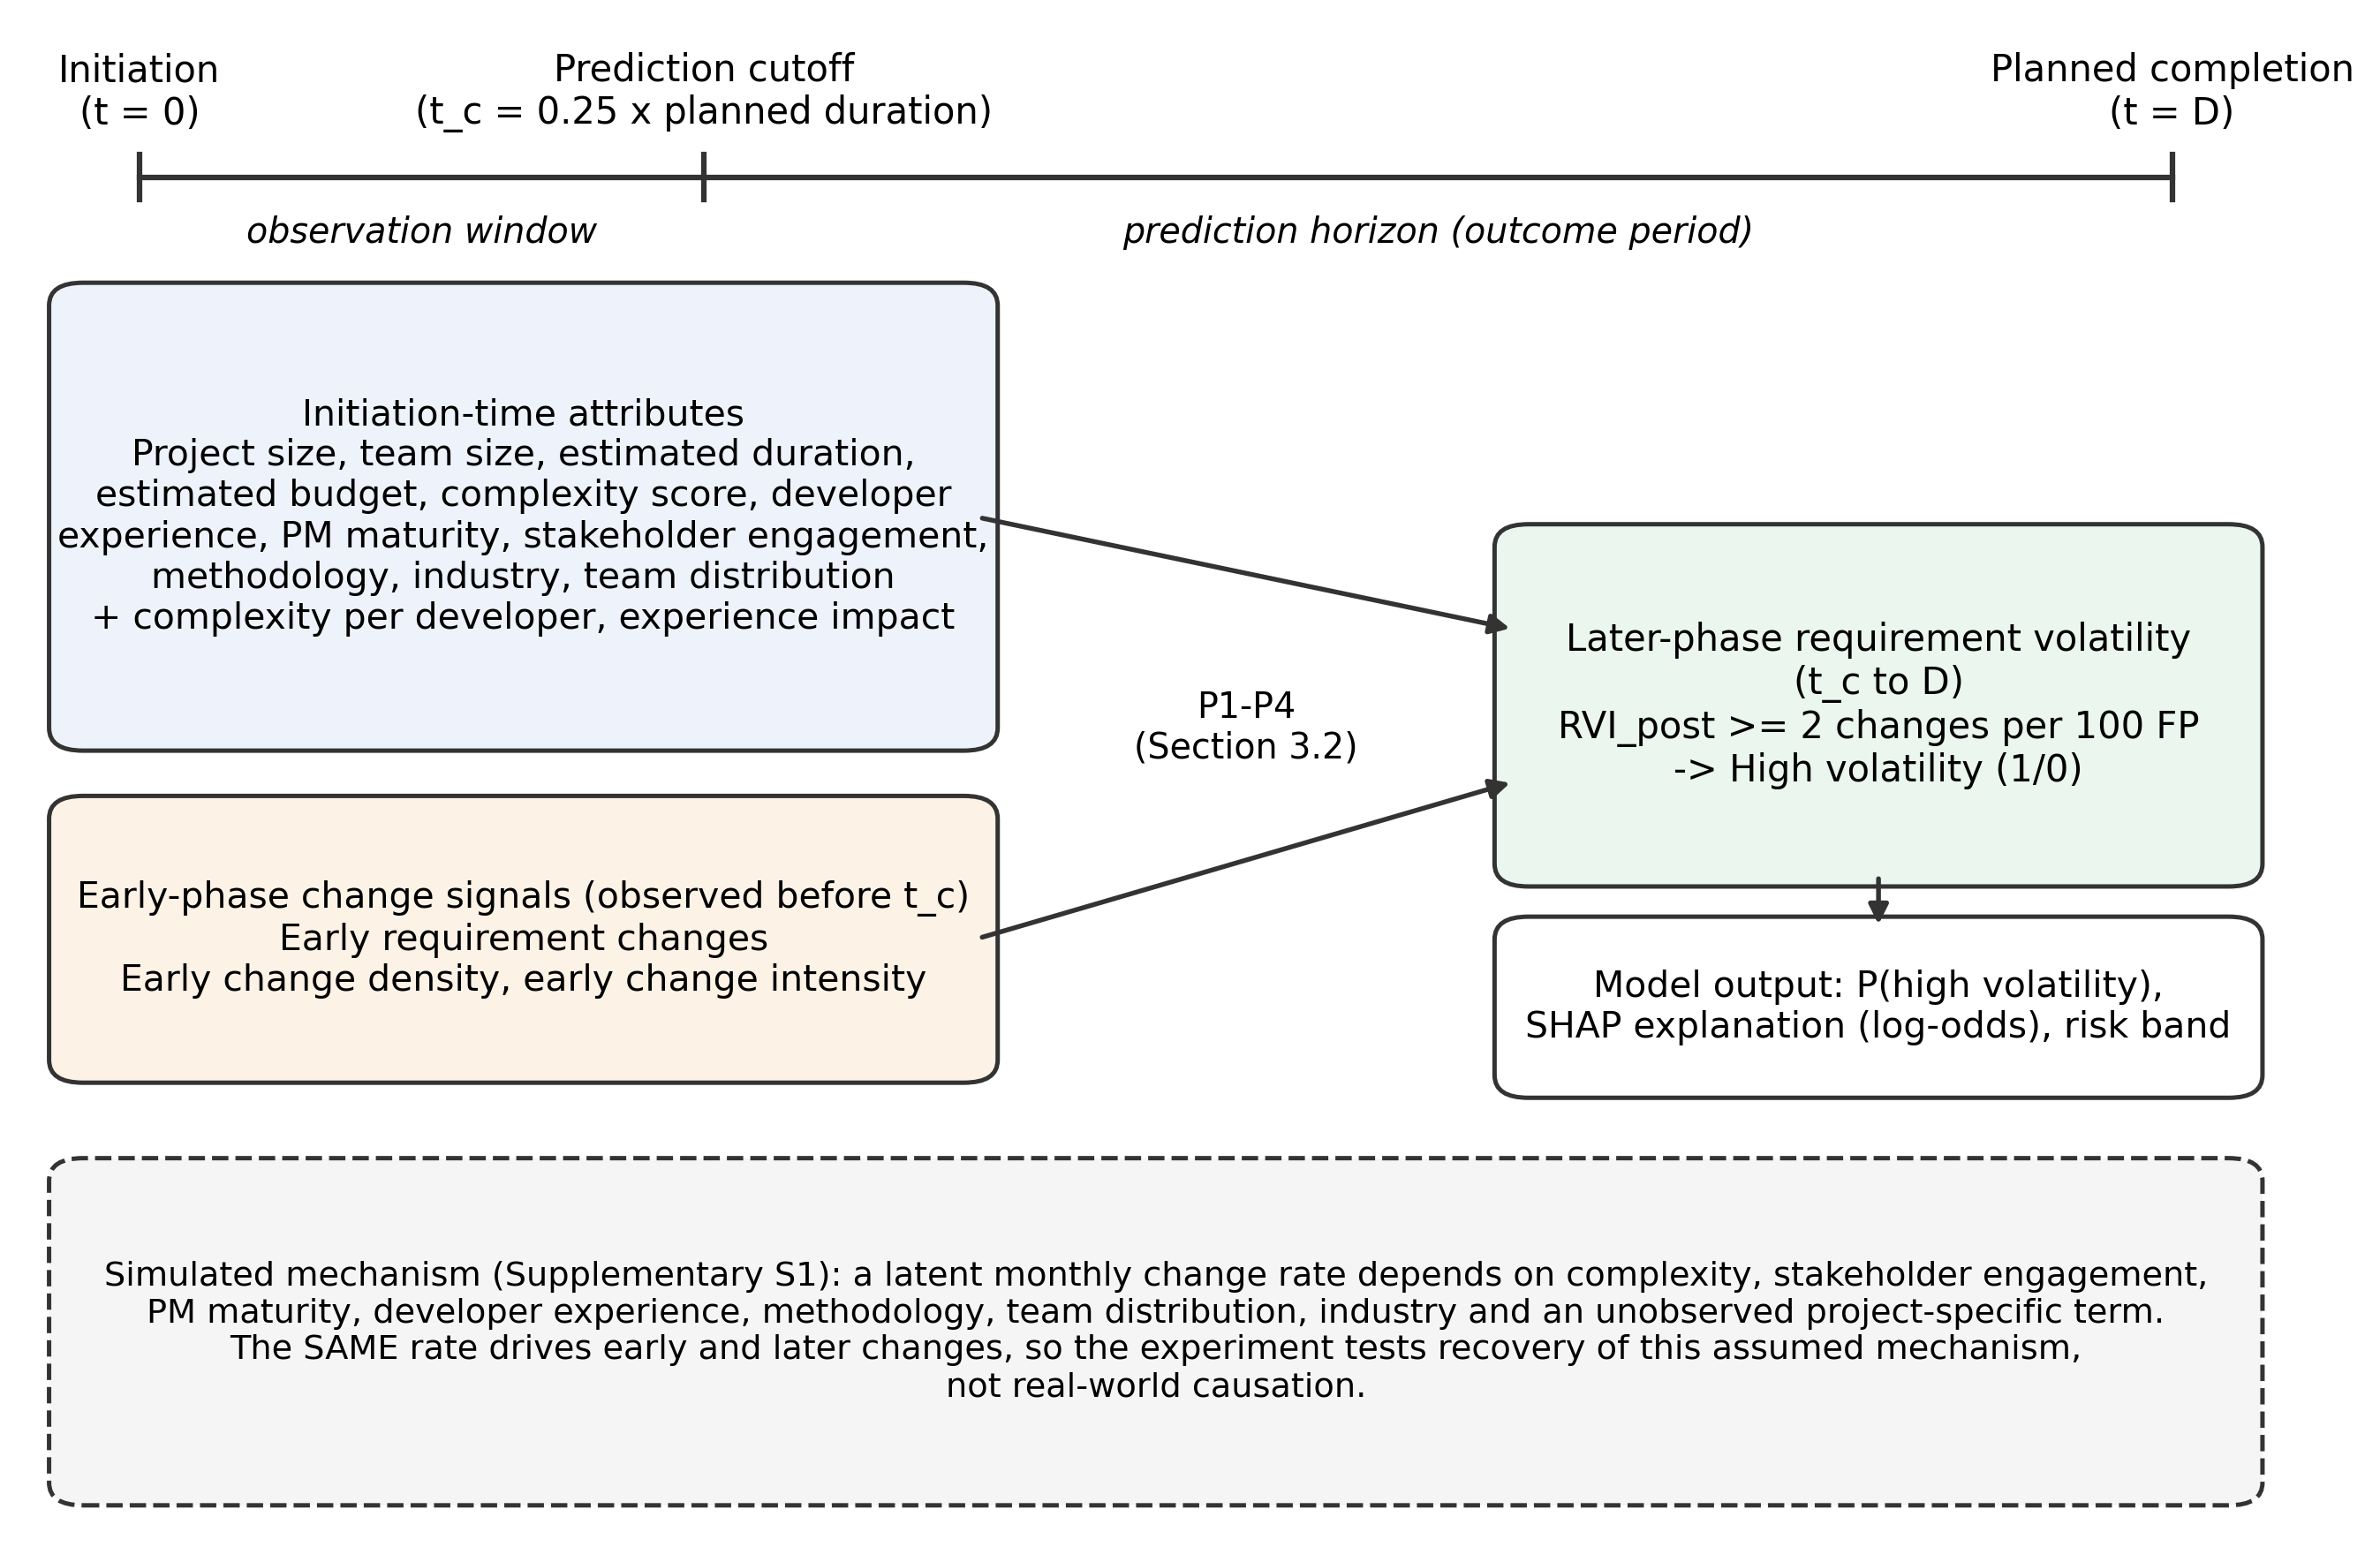

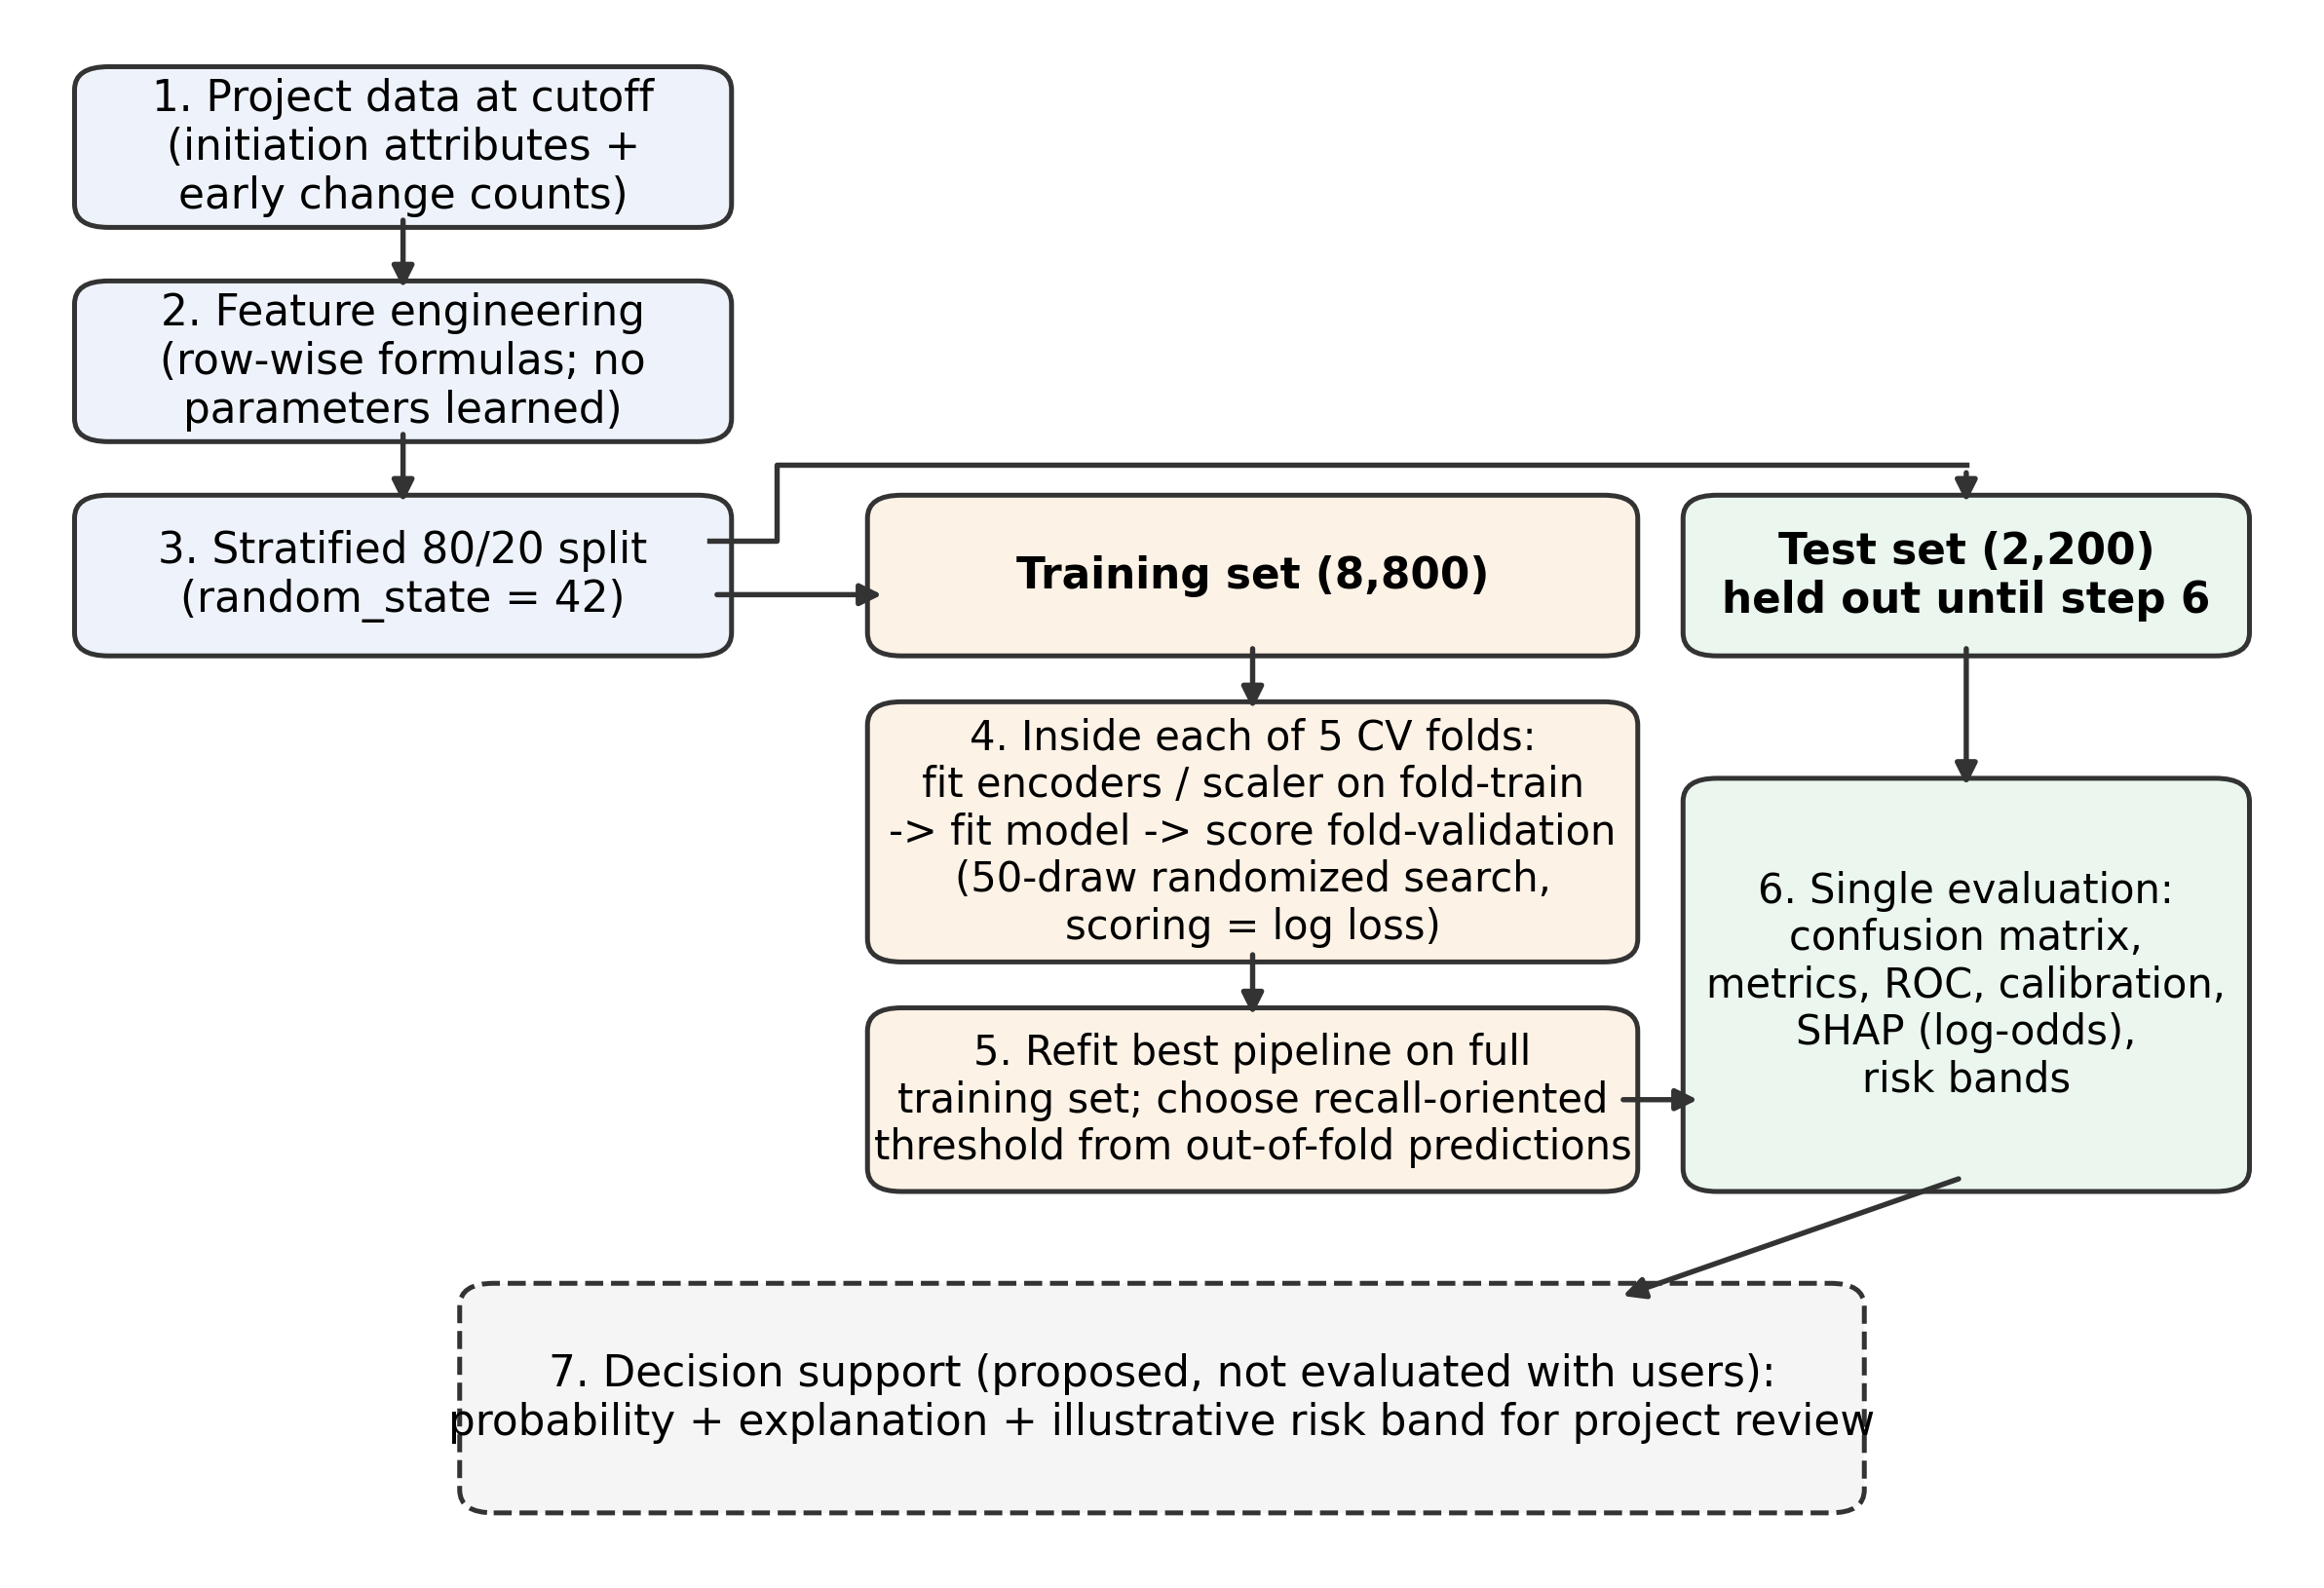

In [32]:
display(Image(os.path.join(fig_dir, 'fig1_conceptual_framework.png'), width=800))
display(Image(os.path.join(fig_dir, 'fig8_pipeline.png'), width=800))

## Notes for reviewers

* Every metric in Tables 3–4 is recomputed from the confusion-matrix counts in the same row, and the code asserts agreement with scikit-learn.
* Engineered-feature formulas are checked against their theoretical maxima on every run (`check_feature_bounds`).
* The test set is touched once, after tuning; the recall-oriented threshold is chosen from out-of-fold training predictions.
* Because the target and predictors share a simulated mechanism, the results show recovery of that mechanism, not real-world causation.